# DX703 Final Project Milestone: Data Exploration and Baseline Modeling

### Due Date: Sunday, November 15th at 11:59pm (with 2 hour plus 1 minute grace period)

**No late submissions!**


## Purpose and scope

This is the **first of two project submissions**. Choose **one** classification dataset—**Food-101** (images) or **HuffPost News Category** (text)—and carry it from initial exploration through a reproducible **baseline model**.

In this milestone you will:

1. Explore both datasets briefly; select and investigate one (**10 pts**).
2. Frame its classification problem, challenges, and evaluation strategy (**15 pts**).
3. Clean and preprocess your data and create reproducible train/validation/test splits (**30 pts**).
4. Train and evaluate a simple baseline using **training and validation data only** (**30 pts**).

**The later final submission** will cover a more capable custom model, a pretrained/transfer-learning model, comparison and selection, a refined final model, and the final technical report. Details of that submission will be posted separately.

### Important conventions

- Retain your chosen dataset for the entire project. Remove the unused dataset's starter cells **after** exploring both.
- Use a fixed random seed, state all data-selection choices and important hyperparameters, and keep the notebook runnable from top to bottom.
- You may use a documented, reproducible subset for experiments if computing resources are limited; explain its size and selection process. Do not represent subset performance as full-dataset performance.
- **Keep the test set untouched in this milestone.** Select models and discuss baseline performance using *validation* results. Save test-set evaluation for the final submission.
- Write each graded explanation in its designated Python string answer variable (`a1a`, `a1b`, etc.). Do not modify the following **Graded Answer** print cells. You may add code cells, plots, or comments as necessary. Follow the approximate word-count guidelines in each problem (100–150 words for Problems 1, 3, and 4; 75–125 words for Problem 2).
- Include an AI-use disclosure at the end in accordance with CDS policy.


### Grading — 85 points total

| Problem | Grading basis | Points |
|---|---|---:|
| 1. Choose the Dataset | 5 questions × 2 pts, including supporting code, tables, and plots | **10** |
| 2. Frame the Problem | 5 questions × 3 pts, including supporting evidence | **15** |
| 3. Data Preparation and Splits | Programming: 18 pts; 4 written answers × 3 pts | **30** |
| 4. Baseline Model | Programming: 18 pts; 4 written answers × 3 pts | **30** |
| **Total** | | **85** |

**How your work will be assessed:** For Problems 1–2, each question will be assessed as a whole, including your written response and the supporting code, tables, or plots. For Problems 3–4, programming and written answers receive separate point allocations.

Programming will be assessed primarily for **correctness and completeness**, with attention to reproducibility, organization, and clarity. Written answers should accurately explain *your own implementation and results*, referring to specific evidence from the notebook. Code may be reviewed and tested, so explanations alone do not earn programming credit. Your submitted notebook must run from beginning to end without errors.

**Use of AI in grading:** We will use AI tools to assist with reviewing code, evaluating written responses, and identifying possible errors or omissions. However, **AI will not make final grading decisions. Every proposed point deduction will be reviewed by a human grader before it is applied.** Human graders retain responsibility for determining and assigning final scores.

In [1]:
# ============================================
# Useful Imports
# ============================================

# --- Standard Libraries
import os
import time
import math
import random
from collections import Counter

# --- Core Data / Numerics
import numpy as np
import pandas as pd

# --- Visualization
import matplotlib.pyplot as plt
import seaborn as sns              # optional
import matplotlib.ticker as mticker  # optional (for formatted axes)

# --- NLP / Tokenization
import spacy                         # used for text preprocessing (HuffPost)

# --- Progress Tracking
from tqdm import tqdm                # optional (nice for loops)

from IPython.display import display

# --- TensorFlow / Keras (Deep Learning)
import tensorflow as tf
from tensorflow.keras import layers, models, Input, callbacks, regularizers, initializers
from tensorflow.keras.callbacks import Callback, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, AdamW
from tensorflow.keras.optimizers.schedules import CosineDecay, ExponentialDecay
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.layers import (
    Dense, Dropout, Flatten, MaxPooling2D, Conv2D,
    SeparableConv2D, GlobalAveragePooling2D, GlobalMaxPooling2D, BatchNormalization
)

# --- (Optional) Classical ML Baseline Tools
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score


# ============================================
# Global Configuration & Small Utilities
# ============================================

# Reproducibility
random_seed = 42
random.seed(random_seed)
np.random.seed(random_seed)
tf.keras.utils.set_random_seed(random_seed)   # sets Python, NumPy, and TensorFlow seeds

# Utility: format seconds as HH:MM:SS

"""
Example usage to time your code:

start_time = time.time()
# ... your code here ...
print("Execution Time:", format_hms(time.time() - start_time))
"""

def format_hms(seconds: float) -> str:
    """Convert seconds to HH:MM:SS format."""
    return time.strftime("%H:%M:%S", time.gmtime(seconds))


In [ ]:
# If needed (in a new env):
# !pip install -U datasets pillow

In [2]:
# --- Hugging Face Datasets
from datasets import load_dataset, DatasetDict
from datasets.features import ClassLabel

### Dataset One (Images): Food-101

#### **Load Food-101 as a Dataset**

> Note: this loads a **Hugging Face `Dataset`**, not NumPy or TensorFlow tensors.
> Each sample is stored as a **dictionary** with two keys — `"image"` (a PIL image object) and `"label"` (an integer class ID).
> You can access columns by name, e.g. `food_all["image"]` or `food_all["label"]`, and check the dataset size with `len(food_all)`.
> Unlike arrays, image sizes and aspect ratios may differ across samples — you’ll handle resizing or normalization later during preprocessing.


In [3]:
food_all = load_dataset("ethz/food101", split="train+validation")  # ~101k images total
label_col = "label"

# Sanity check the label column
assert label_col in food_all.features
assert isinstance(food_all.features[label_col], ClassLabel)

food_label_names = food_all.features[label_col].names
print(f"Total images: {len(food_all):,}  |  Classes: {len(food_label_names)}")

Total images: 101,000  |  Classes: 101


#### **Quick sanity checks (rows, label ids, a few image sizes)**

In [4]:
# First 5 rows: label id → name
for i in range(5):
    y = food_all[i][label_col]
    print(f"row {i}: id={y}, name={food_label_names[y]}")

labels_list = list(food_all[label_col])
print("labels length:", len(labels_list), "unique classes:", len(set(labels_list)))
print("min/max label IDs:", min(labels_list), max(labels_list))

for i in range(3):
    print(f"image {i} size:", food_all[i]["image"].size)  # (W, H)

row 0: id=6, name=beignets
row 1: id=6, name=beignets
row 2: id=6, name=beignets
row 3: id=6, name=beignets
row 4: id=6, name=beignets
labels length: 101000 unique classes: 101
min/max label IDs: 0 100
image 0 size: (384, 512)
image 1 size: (512, 512)
image 2 size: (512, 383)


#### **Visual preview: random 3×3 grid from TRAIN**

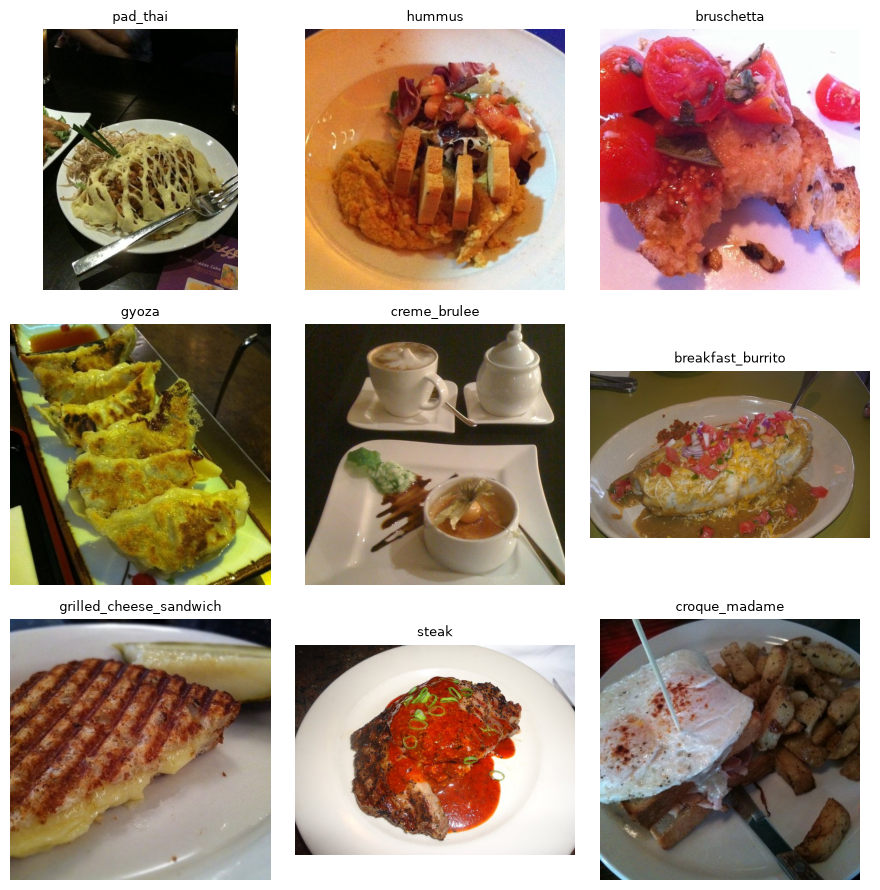

In [5]:
n, cols, seed = 9, 3, 42
idxs = random.Random(seed).sample(range(len(food_all)), n)
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = food_all[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]], fontsize=9)
plt.tight_layout(); plt.show()

---

### Dataset Two (Text): HuffPost Dataset

#### **Load HuffPost (headline + summary + category)**

**Note:** This loads a **Hugging Face `Dataset`**, not a NumPy array or Pandas DataFrame.
- Each record is a **dictionary** with fields such as `"headline"`, `"short_description"`, and `"category"`.
- You can access columns by name (e.g., `huff["headline"]`) and check dataset size with `len(huff)`.
- Treat it as a table of text fields — you’ll handle tokenization and vectorization later during preprocessing.
- The typical BERT-compatible separator is used to construct the sample texts

        `headline [SEP] short-description`



In [6]:
# JSON mirror that preserves fields: headline, short_description, category, authors, link, date
URL = "https://huggingface.co/datasets/khalidalt/HuffPost/resolve/main/News_Category_Dataset_v2.json"
huff_all = load_dataset("json", data_files=URL, split="train")

print(huff_all)
print("Columns:", huff_all.column_names)
print("Total rows:", len(huff_all))

Dataset({
    features: ['category', 'headline', 'authors', 'link', 'short_description', 'date'],
    num_rows: 200853
})
Columns: ['category', 'headline', 'authors', 'link', 'short_description', 'date']
Total rows: 200853


#### **Quick sanity checks (peek at a row)**

In [7]:
ex = huff_all[0]
print("One example:")
print("  category          :", ex.get("category"))
print("  headline          :", (ex.get("headline") or "")[:120])
print("  authors           :", (ex.get("authors") or "")[:120])
print("  short_description :", (ex.get("short_description") or "")[:120])
print("  date              :", ex.get("date"))

One example:
  category          : CRIME
  headline          : There Were 2 Mass Shootings In Texas Last Week, But Only 1 On TV
  authors           : Melissa Jeltsen
  short_description : She left her husband. He killed their children. Just another day in America.
  date              : 2018-05-26 00:00:00


#### **Print 10 random samples (combined text with separator, no truncation)**

In [8]:
# Show k random lines: "headline [SEP] short_description"

k = 10
seed = 7
rng = random.Random(seed)
idxs = rng.sample(range(len(huff_all)), k)

for i in idxs:
    ex = huff_all[i]
    print("  category          :", ex.get("category"))
    print("  headline          :", (ex.get("headline") or ""))
    print("  short_description :", (ex.get("short_description") or ""))
    print("  sample text       :", (ex.get("headline") or "")+'  [SEP]  '+ (ex.get("short_description") or ""))
    print()

  category          : ENTERTAINMENT
  headline          : Pregnant Kim Kardashian Rocks A Sheer Jumpsuit At The Airport
  short_description : Forget what you thought you knew about maternity style, because Kim's changing the game.
  sample text       : Pregnant Kim Kardashian Rocks A Sheer Jumpsuit At The Airport  [SEP]  Forget what you thought you knew about maternity style, because Kim's changing the game.

  category          : WOMEN
  headline          : How I Outran Misogyny
  short_description : "I have started running to retrain the way my brain sees my body, not as a sexual object but as a tool to get things done."
  sample text       : How I Outran Misogyny  [SEP]  "I have started running to retrain the way my brain sees my body, not as a sexual object but as a tool to get things done."

  category          : RELIGION
  headline          : A Prayer From the Mall of America
  short_description : I thank you for the Bloomington Police Department, and the Mall of America Security

#### **(Optional) Save splits to disk (reload later without re-splitting)**

We provide this in case you want to save the dataset to your local disk. Saving Food-101 splits to disk is not recommended unless you have ample local storage (it's huge!). 

In [9]:
# huff_all.save_to_disk("huffpost_splits")        # save
from datasets import load_from_disk
huff = load_from_disk("huffpost_splits")  # reload when needed

---

## Problem 1 — Choose the Dataset (10 pts)

#### Objective
In this problem, you will explore the two provided datasets and select one to use for your final project.  
Your goal is to understand the structure, content, and challenges of the dataset through basic exploratory data analysis (EDA).  
By the end of this milestone notebook, you should be able to explain what makes the dataset interesting, identify potential modeling challenges (e.g., imbalance, ambiguity, quality issues), and justify why it is a good choice for your classification project.


#### What to Do
1. **Load both datasets** and examine the outputs of the template code provided.  
   After this brief inspection, **choose one dataset for your project** and **delete the template code for the other.**  For your chosen dataset, continue with the remaining steps.

2. **Inspect** the dataset's basic properties:  
   - **Number of samples and classes:**  
     Determine how many total examples and distinct categories are present. Verify that the counts match expectations (e.g., 101 food classes or 41 news topics).  
   - **Example records or images:**  
     View several samples to understand the input format, diversity, and potential quality issues.  
     For images, note lighting or composition differences; for text, read a few headlines and summaries to see how expressive they are (done for you in template code). 
   - **Distribution of labels (check for imbalance):**  
     Plot or tabulate label frequencies to see whether some classes dominate. Imbalanced datasets can bias model training and may require special handling.  
   - **Missing or inconsistent data:**  
     Look for empty fields, unreadable images, duplicate entries, or mislabeled samples. Handle or document any issues you find.  
   - **Overlapping or ambiguous class labels:**  
     Identify categories that may not be clearly distinct—e.g., “apple pie” vs. “cheesecake,” or “POLITICS” vs. “WORLD NEWS.”  
     Ambiguity in labels can increase confusion between classes and reduce model accuracy.

3. **Visualize key aspects:**  
   Extend the template code to complete the EDA for your chosen dataset:  
   - **Images:**  
     Create visual summaries to better understand the data (some are implemented in the template code).  
     - Verify that the dataset is balanced across classes.  
     - Display a small grid of random images to check variation in appearance, composition, and background (done in template code).  
     - Compare image sizes to determine whether resizing or normalization will be needed.  
     - Examine lighting and color balance—many web-scraped photos vary widely in brightness, saturation, and white balance.  
   - **Text:**  
     Visualize class balance and linguistic properties (some implemented in the template code).  
     - Plot the number of samples per label to confirm class balance or imbalance.  
     - Compute basic text statistics such as average word count or vocabulary size.  
     - Examine examples for duplicates, near-duplicates, or entries that might fit multiple categories.  
     - *(Optional)* Generate a word-frequency plot or word cloud to highlight distinctive terms for a few classes.

4. **Answer the graded questions below.**


### Check for Corrupted Images

In [ ]:
from PIL import Image as PILImage
from datasets import Image as HFImage
import io

food_all_copy = load_dataset("ethz/food101", split="train+validation")

# keep images in terms of bytes rather than decoded
food_all_copy = food_all_copy.cast_column('image', HFImage(decode=False))

corrupted_image_idx = []

for idx, img in enumerate(food_all_copy):
    try:
        image_bytes = img['image']['bytes']

        if image_bytes is None:
            raise ValueError('Image bytes are None')

        # verify image integrity
        with PILImage.open(io.BytesIO(image_bytes)) as i:
            i.verify()

    except (IOError, SyntaxError, ValueError, TypeError) as e:
        print(f"Corrupted image found at index {idx}: {e}")
        corrupted_image_idx.append(idx)

print(f'Total corrupted images: {len(corrupted_image_idx)}')
print(f'Corrupted indices: {corrupted_image_idx}')

Total corrupted images: 0
Corrupted indices: []


### EDA

Class Counts: {'beignets': 1000, 'prime_rib': 1000, 'ramen': 1000, 'hamburger': 1000, 'bruschetta': 1000, 'chicken_wings': 1000, 'pork_chop': 1000, 'greek_salad': 1000, 'sashimi': 1000, 'risotto': 1000, 'pizza': 1000, 'eggs_benedict': 1000, 'guacamole': 1000, 'chocolate_cake': 1000, 'miso_soup': 1000, 'apple_pie': 1000, 'fried_calamari': 1000, 'fried_rice': 1000, 'panna_cotta': 1000, 'hummus': 1000, 'carrot_cake': 1000, 'beet_salad': 1000, 'garlic_bread': 1000, 'hot_dog': 1000, 'steak': 1000, 'tiramisu': 1000, 'fish_and_chips': 1000, 'caesar_salad': 1000, 'tuna_tartare': 1000, 'pancakes': 1000, 'chocolate_mousse': 1000, 'lasagna': 1000, 'pad_thai': 1000, 'cheesecake': 1000, 'baklava': 1000, 'ice_cream': 1000, 'red_velvet_cake': 1000, 'tacos': 1000, 'foie_gras': 1000, 'grilled_cheese_sandwich': 1000, 'frozen_yogurt': 1000, 'seaweed_salad': 1000, 'breakfast_burrito': 1000, 'crab_cakes': 1000, 'strawberry_shortcake': 1000, 'beef_tartare': 1000, 'mussels': 1000, 'dumplings': 1000, 'creme_b

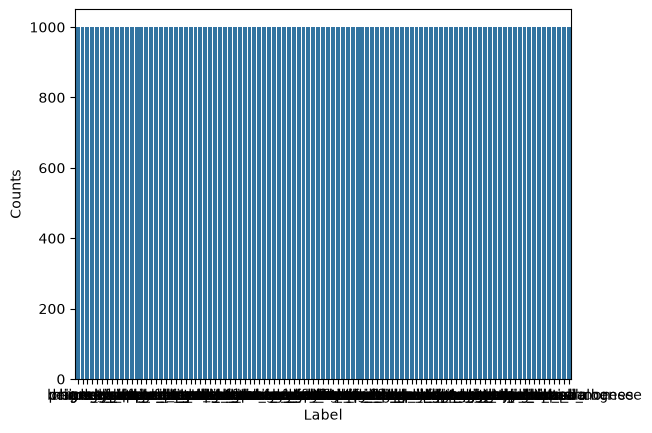

In [10]:
# Your code here, add as many cells as you like. Provide organization and structure by appropriate comments, labels, and variable names. Explain what
# you are doing in case you come back to this in a year. 

# Get the class balance for the food101 dataset
class_counts  = Counter(food_all['label'])
label_names   = food_all.features['label'].names
class_balance = {label_names[label_id]: count for label_id, count in class_counts.items()}
print('Class Counts:', class_balance)
print('Unique Counts per Class:', pd.Series(class_balance.values()).unique())

# check to see if there are any images from food101 dataset that don't have any labels
df = food_all.to_pandas()
print('Total images without labels:', df['label'].isna().sum())

# plot class balance
data = {'Label': class_balance.keys(),
        'Counts': class_balance.values()}
df = pd.DataFrame(data)
sns.barplot(df, x='Label', y='Counts')
plt.show()

In [11]:
import warnings

# Suppress only the Pillow TIFF tag warnings:           
#       Used Gemini: https://share.gemini.google/GqmCJU5IcIhZ
warnings.filterwarnings('ignore', category=UserWarning, module='PIL.TiffImagePlugin')

# gather all image sizes (Width, Height)
img_dimensions = []
for i in food_all:
    img_dimensions.append(i['image'].size)

# check the unique image dimensions
unique_dimensions = list(set(img_dimensions))
print('Unique image dimensions:', unique_dimensions)
print('Unique Dimension Count:', len(unique_dimensions))

img_sizes = []  # regardless of orientation
for i in unique_dimensions:
    w, h = i    # gets width and height from dimension tuple (width, height)
    size = w * h
    img_sizes.append(size)
unique_sizes = set(img_sizes)
print('Unique image sizes:', unique_sizes)
print('Unique image size count:', len(unique_sizes))

Unique image dimensions: [(308, 512), (319, 512), (453, 512), (512, 409), (512, 418), (512, 427), (512, 436), (376, 512), (512, 445), (510, 512), (415, 512), (512, 274), (512, 283), (512, 292), (512, 301), (338, 512), (512, 310), (494, 512), (483, 512), (472, 512), (377, 512), (512, 404), (445, 512), (512, 413), (512, 422), (512, 431), (512, 440), (512, 269), (512, 278), (512, 287), (512, 296), (512, 305), (464, 512), (475, 512), (512, 390), (349, 512), (512, 399), (512, 408), (512, 417), (512, 426), (417, 512), (456, 512), (512, 273), (512, 511), (512, 282), (512, 291), (379, 512), (368, 512), (390, 512), (512, 376), (512, 385), (512, 394), (447, 512), (512, 403), (341, 512), (330, 512), (512, 412), (486, 512), (512, 241), (512, 259), (409, 512), (512, 268), (512, 506), (512, 277), (437, 512), (448, 512), (371, 512), (505, 512), (512, 371), (410, 512), (512, 380), (399, 512), (512, 389), (512, 398), (512, 407), (333, 512), (322, 512), (467, 512), (512, 236), (512, 254), (512, 492), (5

In [12]:
from PIL import Image, ImageStat

def rms_brightness(image):
    """
        Greyscales image and then calculates the root mean square pixel value from 0-256 (0: pure black, 255: pure white)
            Source: https://stackoverflow.com/questions/3490727/what-are-some-methods-to-analyze-image-brightness-using-python
    """
    img  = image.convert('L')
    stat = ImageStat.Stat(img)
    return stat.rms[0]


def perceived_brightness(image):
    """
        Averages RBG values of image, then returns the human perceived brightness value 0-1 (0: pure black, 1: pure white)
            Sources: https://alienryderflex.com/hsp.html https://stackoverflow.com/questions/3490727/what-are-some-methods-to-analyze-image-brightness-using-python
    """
    img   = image.convert('RGB') # ensure all images are RGB
    stat  = ImageStat.Stat(img)
    r,g,b = stat.mean
    return math.sqrt(0.299*(r**2) + 0.587*(g**2) + 0.114*(b**2))

# For all images, record their labels and brightness metrics
brightness_data = []
for i in food_all:
    brightness_data.append({
        'Food Label'            : label_names[i['label']],
        'RMS Brightness'        : rms_brightness(i['image']),
        'Perceived Brightness'  : perceived_brightness(i['image'])
    })
img_characteristics = pd.DataFrame(brightness_data)
img_characteristics.describe()

,RMS Brightness,Perceived Brightness
count,101000.000000,101000.000000
mean,133.247694,119.780921
std,26.084445,27.659153
min,2.851318,2.905803
25%,117.446433,102.035896
50%,133.671916,119.896454
75%,150.476857,138.434911
max,240.370416,236.354698


In [13]:
# Assess the mean brightness metrics per classification
food_label_brightness = img_characteristics.groupby('Food Label')[['RMS Brightness', 'Perceived Brightness']].mean()
perceived_brightness_sorted = food_label_brightness['Perceived Brightness'].sort_values(ascending=False)
rms_brightness_sorted       = food_label_brightness['RMS Brightness'].sort_values(ascending=False)

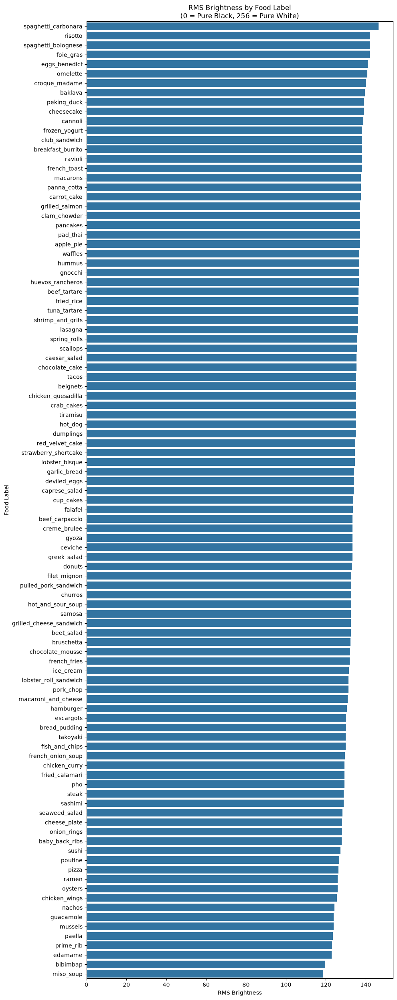

In [14]:
plt.figure(figsize=(10, 25))
sns.barplot(
    x=rms_brightness_sorted.values,
    y=rms_brightness_sorted.index,
    orient='h'
)
plt.title('RMS Brightness by Food Label\n(0 = Pure Black, 256 = Pure White)')
plt.xlabel('RMS Brightness')
plt.tight_layout()

In [15]:
# get numeric/string label pair for easy lookup
numeric_labels = set(food_all['label'])
lookup_data = [
    {
        'Label Index': num_label,
        'Label Name': food_label_names[num_label]
    }
    for num_label in numeric_labels
]
LABELS_IDX_LOOKUP = pd.DataFrame(lookup_data)
LABELS_IDX_LOOKUP.head()

,Label Index,Label Name
0,0,apple_pie
1,1,baby_back_ribs
2,2,baklava
3,3,beef_carpaccio
4,4,beef_tartare


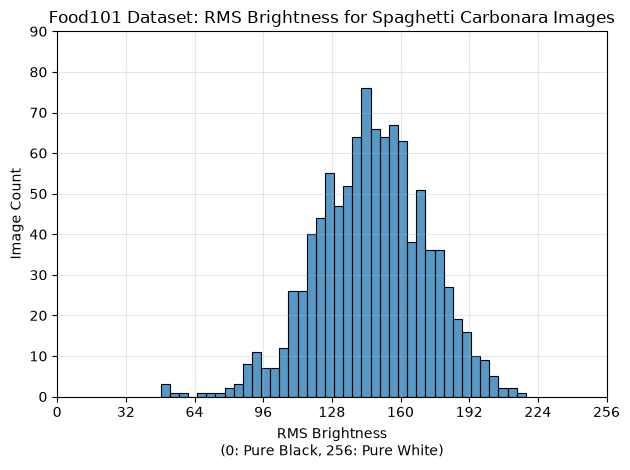

Min RMS Brightness       : 48.1971
Max RMS Brightness       : 218.4245
Median RMS Brightness    : 147.0399
RMS Brightness Range     : 170.2274


In [16]:
# Visualizing maximum RMS Brightness Food Label
max_brightness_idx   = rms_brightness_sorted.argmax()
max                  = rms_brightness_sorted.iloc[max_brightness_idx]
max_label            = rms_brightness_sorted.idxmax()

# max_brightness_idx, max_label, max

# Get label index, all images with label index value, and record their RMS brightness values
max_idx             = LABELS_IDX_LOOKUP[LABELS_IDX_LOOKUP['Label Name'] == max_label]['Label Index'].iloc[0]
max_images          = [i for i in food_all if i['label'] == max_idx]
rms_brightness_max  = [rms_brightness(i['image']) for i in max_images]

sns.histplot(rms_brightness_max, bins=40)
plt.title(f'Food101 Dataset: RMS Brightness for {max_label.replace("_", " ").title()} Images')
plt.ylabel('Image Count')
plt.xlabel('RMS Brightness\n(0: Pure Black, 256: Pure White)')

plt.xlim(0, 256)
plt.xticks(range(0, 257, 32))       # ticks every 32 (8 total ticks)
plt.yticks(range(0, 91, 10))        # frequency ticks 0-90 (checked between three RMS histograms to find common maximum y tick for easier comparability)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Min RMS Brightness       : {np.min(rms_brightness_max):.4f}')
print(f'Max RMS Brightness       : {np.max(rms_brightness_max):.4f}')
print(f'Median RMS Brightness    : {np.median(rms_brightness_max):.4f}')
print(f'RMS Brightness Range     : {(np.max(rms_brightness_max) - np.min(rms_brightness_max)):.4f}')

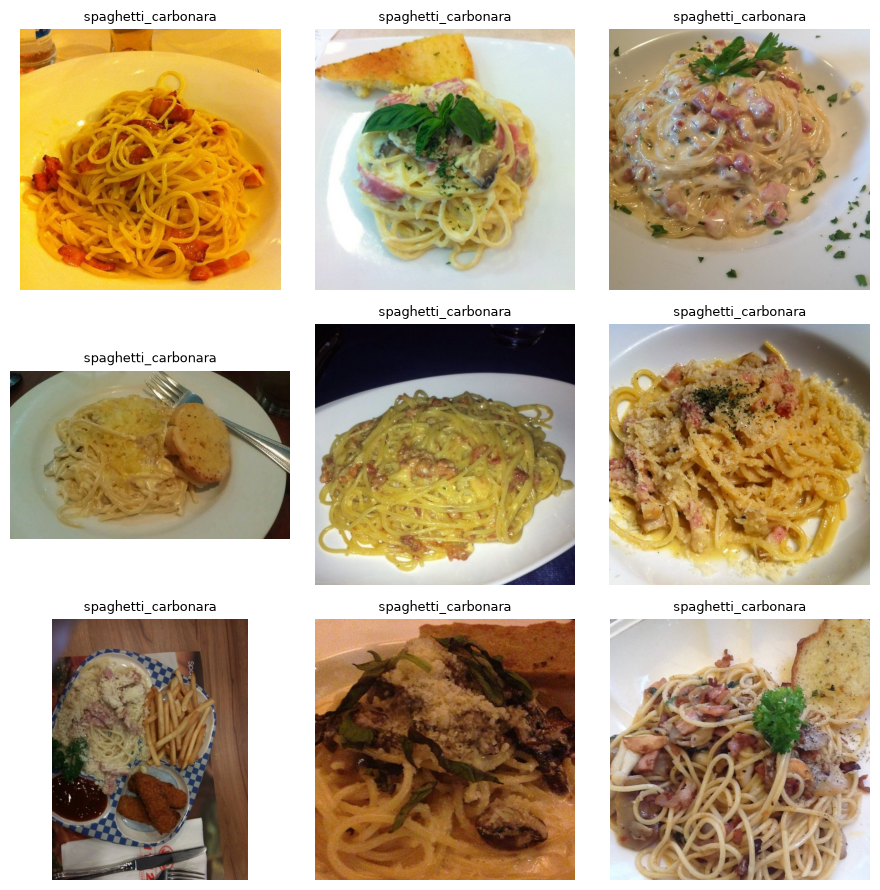

In [17]:
# Visualizing a sample of max RMS brightness food images
numeric_label  = LABELS_IDX_LOOKUP[LABELS_IDX_LOOKUP['Label Name'] == max_label]['Label Index'].iloc[0]
max_rms_images = [i for i in food_all if i['label'] == numeric_label]

n, cols, seed = 9, 3, 42
idxs = random.Random(seed).sample(range(len(max_rms_images)), n)
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = max_rms_images[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]], fontsize=9)
plt.tight_layout(); plt.show()

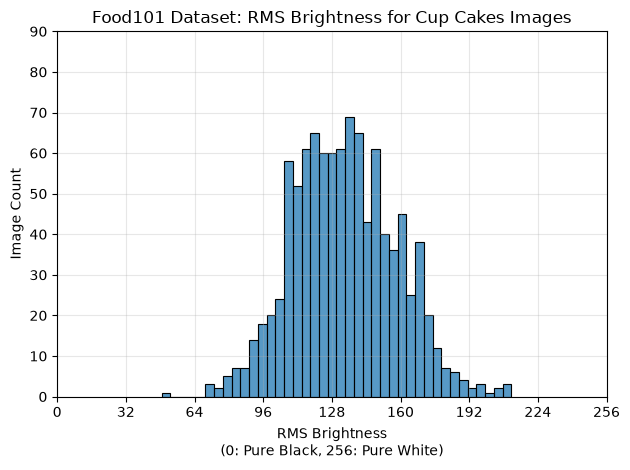

Min RMS Brightness       : 48.6810
Max RMS Brightness       : 211.6392
Median RMS Brightness    : 132.8360
RMS Brightness Range     : 162.9582


In [18]:
# Visualizing median RMS Brightness Food Label
median_brightness_idx   = len(rms_brightness_sorted) // 2
median                  = rms_brightness_sorted.iloc[median_brightness_idx]
median_label            = rms_brightness_sorted.index[median_brightness_idx]

# median_brightness_idx, median_label, median

# Get label index, all images with label index value, and record their RMS brightness values
median_idx             = LABELS_IDX_LOOKUP[LABELS_IDX_LOOKUP['Label Name'] == median_label]['Label Index'].iloc[0]
median_images          = [i for i in food_all if i['label'] == median_idx]
rms_brightness_median  = [rms_brightness(i['image']) for i in median_images]

sns.histplot(rms_brightness_median, bins=40)
plt.title(f'Food101 Dataset: RMS Brightness for {median_label.replace("_", " ").title()} Images')
plt.ylabel('Image Count')
plt.xlabel('RMS Brightness\n(0: Pure Black, 256: Pure White)')

plt.xlim(0, 256)
plt.xticks(range(0, 257, 32))       # ticks every 32 (8 total ticks)
plt.yticks(range(0, 91, 10))        # frequency ticks 0-90 (checked between three RMS histograms to find common maximum y tick for easier comparability)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Min RMS Brightness       : {np.min(rms_brightness_median):.4f}')
print(f'Max RMS Brightness       : {np.max(rms_brightness_median):.4f}')
print(f'Median RMS Brightness    : {np.median(rms_brightness_median):.4f}')
print(f'RMS Brightness Range     : {(np.max(rms_brightness_median) - np.min(rms_brightness_median)):.4f}')

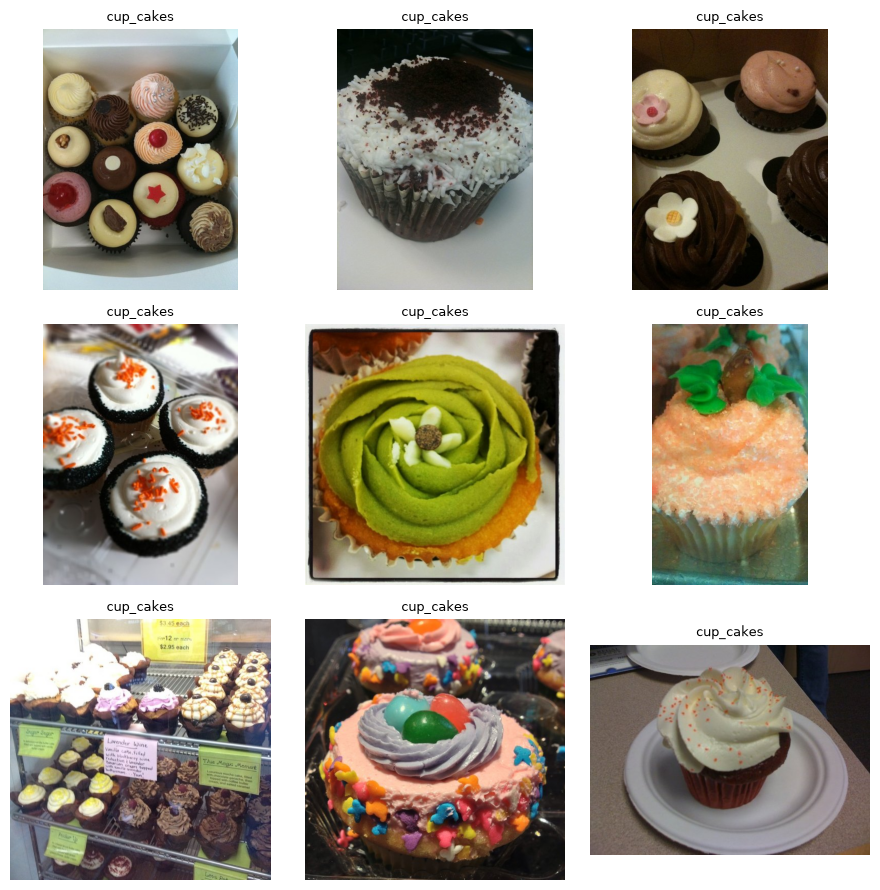

In [19]:
# Visualizing a sample of median RMS brightness food images
numeric_label  = LABELS_IDX_LOOKUP[LABELS_IDX_LOOKUP['Label Name'] == median_label]['Label Index'].iloc[0]
median_rms_images = [i for i in food_all if i['label'] == numeric_label]

n, cols, seed = 9, 3, 42
idxs = random.Random(seed).sample(range(len(median_rms_images)), n)
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = median_rms_images[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]], fontsize=9)
plt.tight_layout(); plt.show()

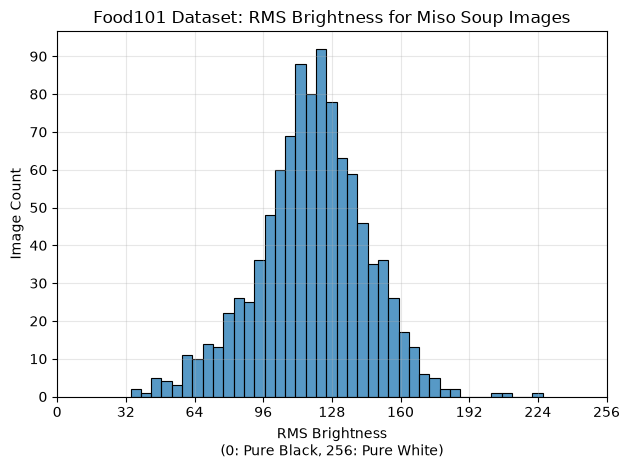

Min RMS Brightness       : 34.2031
Max RMS Brightness       : 226.3113
Median RMS Brightness    : 119.6407
RMS Brightness Range     : 192.1082


In [20]:
# Visualizing minimum RMS Brightness Food Label
min_brightness_idx   = rms_brightness_sorted.argmin()
min                  = rms_brightness_sorted.iloc[median_brightness_idx]
min_label            = rms_brightness_sorted.idxmin()

# min_brightness_idx, min_label, min

# Get label index, all images with label index value, and record their RMS brightness values
min_idx             = LABELS_IDX_LOOKUP[LABELS_IDX_LOOKUP['Label Name'] == min_label]['Label Index'].iloc[0]
min_images          = [i for i in food_all if i['label'] == min_idx]
rms_brightness_min  = [rms_brightness(i['image']) for i in min_images]

sns.histplot(rms_brightness_min, bins=40)
plt.title(f'Food101 Dataset: RMS Brightness for {min_label.replace("_", " ").title()} Images')
plt.ylabel('Image Count')
plt.xlabel('RMS Brightness\n(0: Pure Black, 256: Pure White)')

plt.xlim(0, 256)
plt.xticks(range(0, 257, 32))       # ticks every 32 (8 total ticks)
plt.yticks(range(0, 91, 10))        # frequency ticks 0-90 (checked between three RMS histograms to find common maximum y tick for easier comparability)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Min RMS Brightness       : {np.min(rms_brightness_min):.4f}')
print(f'Max RMS Brightness       : {np.max(rms_brightness_min):.4f}')
print(f'Median RMS Brightness    : {np.median(rms_brightness_min):.4f}')
print(f'RMS Brightness Range     : {(np.max(rms_brightness_min) - np.min(rms_brightness_min)):.4f}')

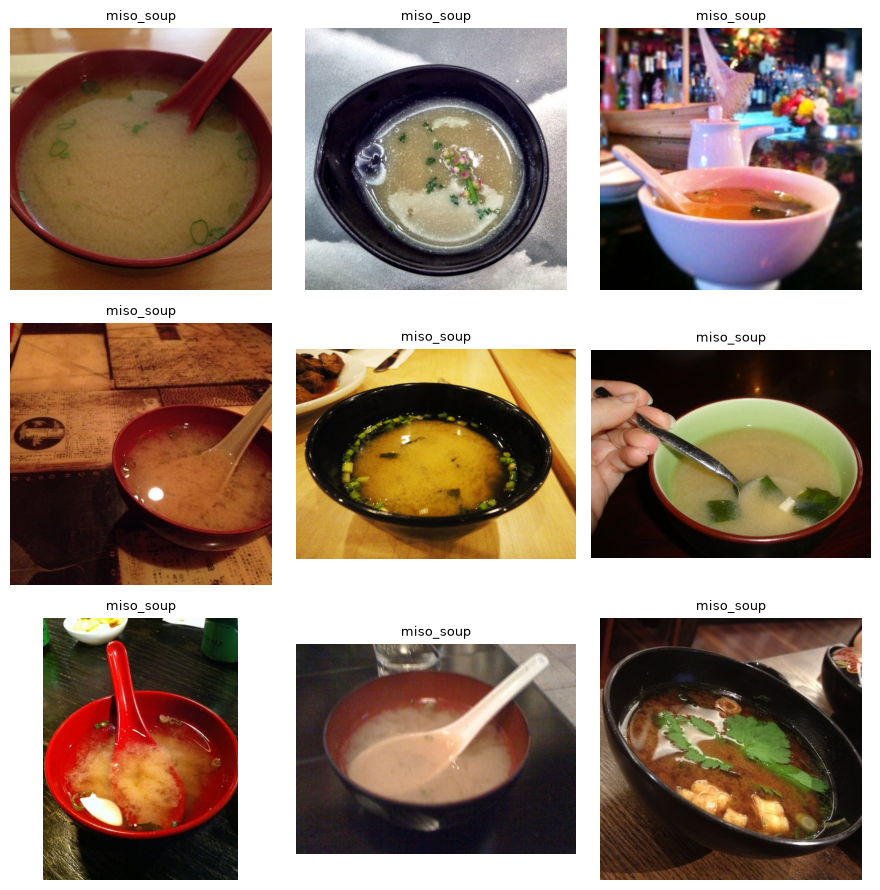

In [21]:
# Visualizing a sample of minimum RMS brightness food images
numeric_label  = LABELS_IDX_LOOKUP[LABELS_IDX_LOOKUP['Label Name'] == min_label]['Label Index'].iloc[0]
min_rms_images = [i for i in food_all if i['label'] == numeric_label]

n, cols, seed = 9, 3, 42
idxs = random.Random(seed).sample(range(len(min_rms_images)), n)
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = min_rms_images[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]], fontsize=9)
plt.tight_layout(); plt.show()

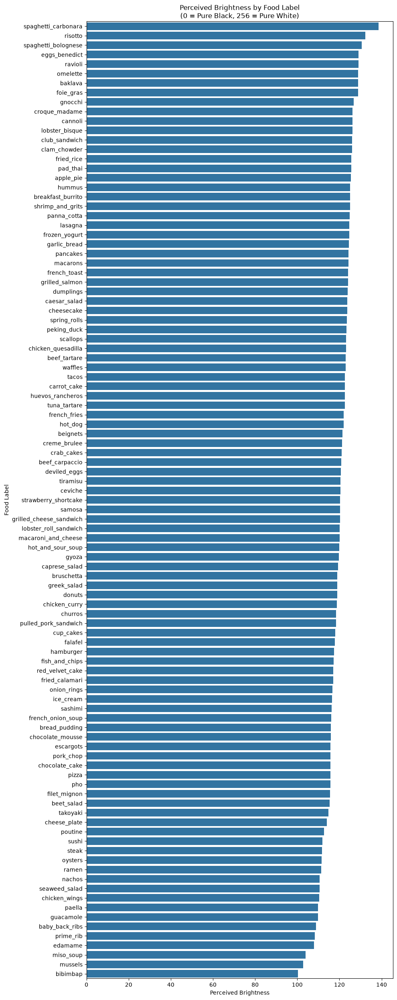

In [22]:
plt.figure(figsize=(10, 25))
sns.barplot(
    x=perceived_brightness_sorted.values,
    y=perceived_brightness_sorted.index,
    orient='h'
)
plt.title('Perceived Brightness by Food Label\n(0 = Pure Black, 256 = Pure White)')
plt.xlabel('Perceived Brightness')
plt.tight_layout()

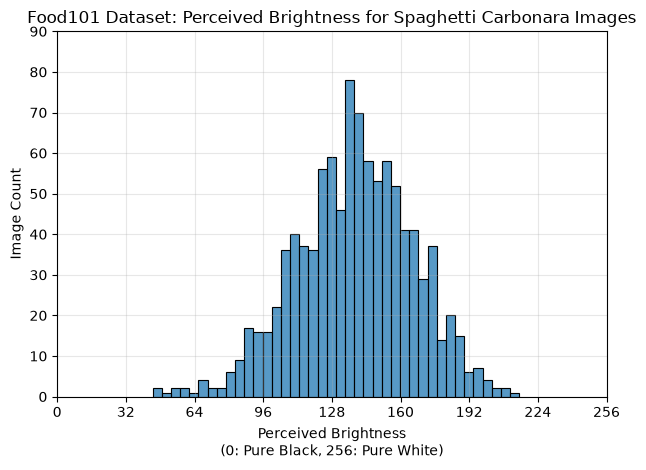

Min Perceived Brightness       : 44.4906
Max Perceived Brightness       : 215.3382
Median Perceived Brightness    : 139.0925
Perceived Brightness Range     : 170.8476


In [23]:
# Visualizing maximum Perceived Brightness Food Label
max_brightness_idx   = perceived_brightness_sorted.argmax()
max                  = perceived_brightness_sorted.iloc[max_brightness_idx]
max_label            = perceived_brightness_sorted.idxmax()

# max_brightness_idx, max_label, max

# Get label index, all images with label index value, and record their RMS brightness values
max_idx                   = LABELS_IDX_LOOKUP[LABELS_IDX_LOOKUP['Label Name'] == max_label]['Label Index'].iloc[0]
max_images                = [i for i in food_all if i['label'] == max_idx]
perceived_brightness_max  = [perceived_brightness(i['image']) for i in max_images]

sns.histplot(perceived_brightness_max, bins=40)
plt.title(f'Food101 Dataset: Perceived Brightness for {max_label.replace("_", " ").title()} Images')
plt.ylabel('Image Count')
plt.xlabel('Perceived Brightness\n(0: Pure Black, 256: Pure White)')

plt.xlim(0, 256)
plt.xticks(range(0, 257, 32))       # ticks every 32 (8 total ticks)
plt.yticks(range(0, 91, 10))        # frequency ticks 0-90 (checked between three perceived brightness histograms to find common maximum y tick for easier comparability)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Min Perceived Brightness       : {np.min(perceived_brightness_max):.4f}')
print(f'Max Perceived Brightness       : {np.max(perceived_brightness_max):.4f}')
print(f'Median Perceived Brightness    : {np.median(perceived_brightness_max):.4f}')
print(f'Perceived Brightness Range     : {(np.max(perceived_brightness_max) - np.min(perceived_brightness_max)):.4f}')

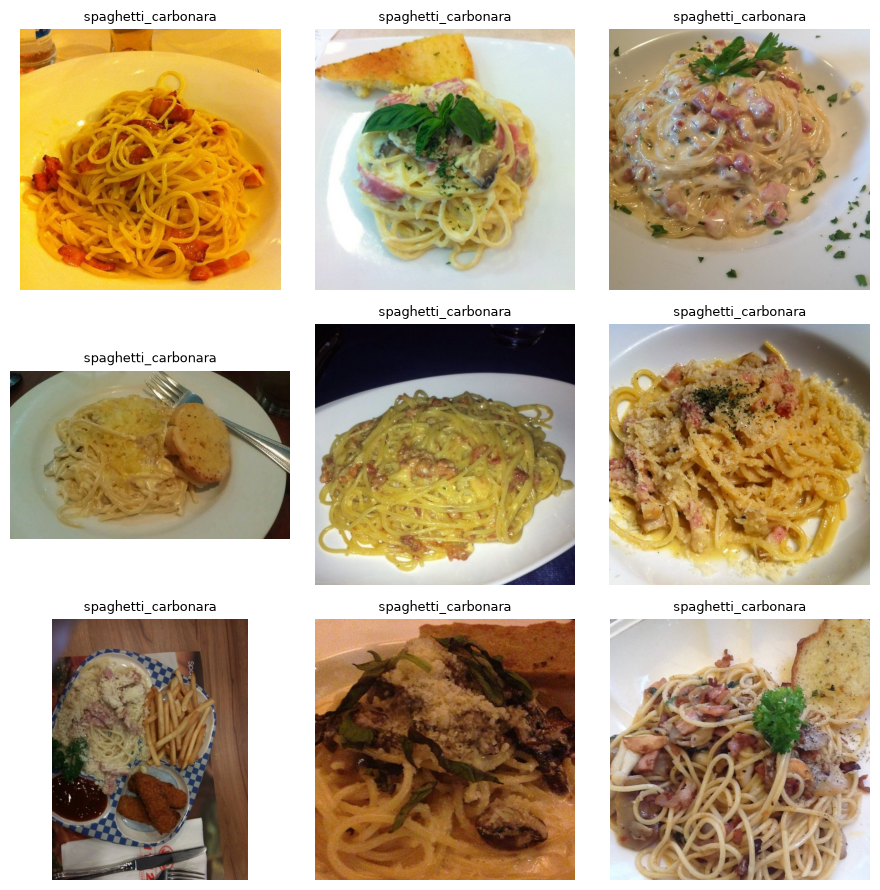

In [24]:
# Visualizing a sample of maximum perceived brightness food images
numeric_label                   = LABELS_IDX_LOOKUP[LABELS_IDX_LOOKUP['Label Name'] == max_label]['Label Index'].iloc[0]
min_perceived_brightness_images = [i for i in food_all if i['label'] == numeric_label]

n, cols, seed = 9, 3, 42
idxs = random.Random(seed).sample(range(len(min_perceived_brightness_images)), n)
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = min_perceived_brightness_images[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]], fontsize=9)
plt.tight_layout(); plt.show()

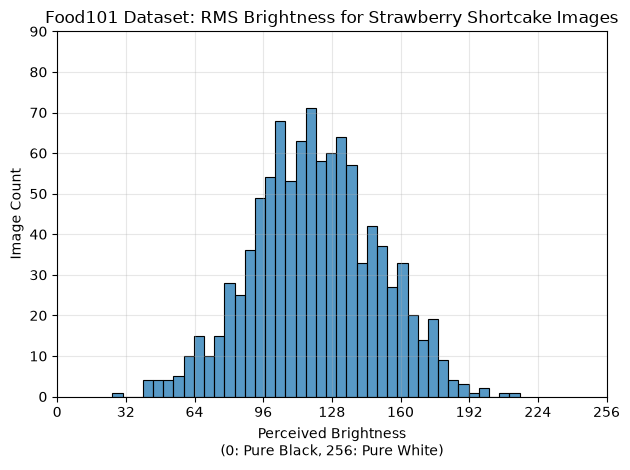

Min Perceived Brightness       : 25.7267
Max Perceived Brightness       : 215.4764
Median Perceived Brightness    : 119.6653
Perceived Brightness Range     : 189.7496


In [25]:
# Visualizing median Perceived Brightness Food Label
median_brightness_idx   = len(perceived_brightness_sorted) // 2
median                  = perceived_brightness_sorted.iloc[median_brightness_idx]
median_label            = perceived_brightness_sorted.index[median_brightness_idx]

# median_brightness_idx, median_label, median

# Get label index, all images with label index value, and record their RMS brightness values
median_idx                   = LABELS_IDX_LOOKUP[LABELS_IDX_LOOKUP['Label Name'] == median_label]['Label Index'].iloc[0]
median_images                = [i for i in food_all if i['label'] == median_idx]
perceived_brightness_median  = [perceived_brightness(i['image']) for i in median_images]

sns.histplot(perceived_brightness_median, bins=40)
plt.title(f'Food101 Dataset: RMS Brightness for {median_label.replace("_", " ").title()} Images')
plt.ylabel('Image Count')
plt.xlabel('Perceived Brightness\n(0: Pure Black, 256: Pure White)')

plt.xlim(0, 256)
plt.xticks(range(0, 257, 32))       # ticks every 32 (8 total ticks)
plt.yticks(range(0, 91, 10))        # frequency ticks 0-90 (checked between three perceived brightness histograms to find common maximum y tick for easier comparability)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Min Perceived Brightness       : {np.min(perceived_brightness_median):.4f}')
print(f'Max Perceived Brightness       : {np.max(perceived_brightness_median):.4f}')
print(f'Median Perceived Brightness    : {np.median(perceived_brightness_median):.4f}')
print(f'Perceived Brightness Range     : {(np.max(perceived_brightness_median) - np.min(perceived_brightness_median)):.4f}')

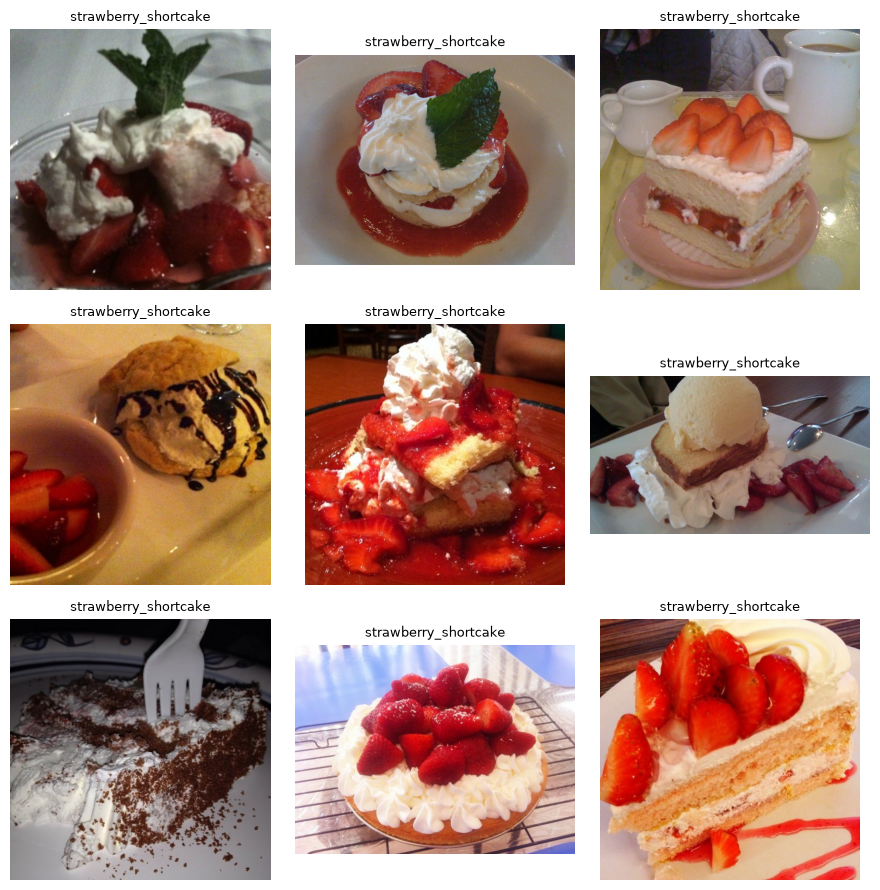

In [26]:
# Visualizing a sample of median perceived brightness food images
numeric_label                   = LABELS_IDX_LOOKUP[LABELS_IDX_LOOKUP['Label Name'] == median_label]['Label Index'].iloc[0]
med_perceived_brightness_images = [i for i in food_all if i['label'] == numeric_label]

n, cols, seed = 9, 3, 42
idxs = random.Random(seed).sample(range(len(med_perceived_brightness_images)), n)
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = med_perceived_brightness_images[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]], fontsize=9)
plt.tight_layout(); plt.show()

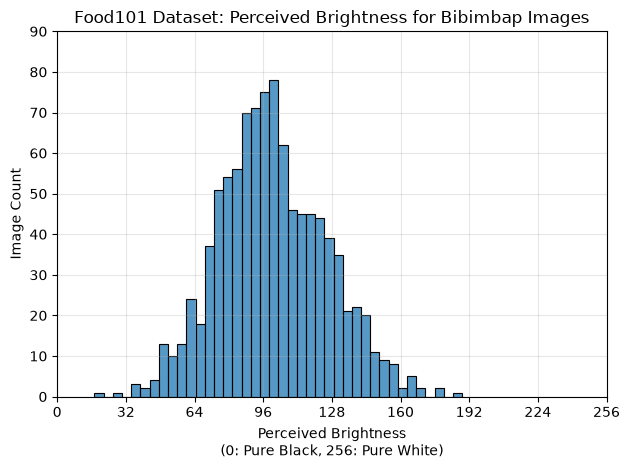

Min Perceived Brightness       : 17.3930
Max Perceived Brightness       : 188.7650
Median Perceived Brightness    : 98.7028
Perceived Brightness Range     : 171.3721


In [27]:
# Visualizing minimum Perceived Brightness Food Label
min_brightness_idx   = perceived_brightness_sorted.argmin()
min                  = perceived_brightness_sorted.iloc[min_brightness_idx]
min_label            = perceived_brightness_sorted.idxmin()

# min_brightness_idx, min_label, min

# Get label index, all images with label index value, and record their RMS brightness values
min_idx                   = LABELS_IDX_LOOKUP[LABELS_IDX_LOOKUP['Label Name'] == min_label]['Label Index'].iloc[0]
min_images                = [i for i in food_all if i['label'] == min_idx]
perceived_brightness_min  = [perceived_brightness(i['image']) for i in min_images]

sns.histplot(perceived_brightness_min, bins=40)
plt.title(f'Food101 Dataset: Perceived Brightness for {min_label.replace("_", " ").title()} Images')
plt.ylabel('Image Count')
plt.xlabel('Perceived Brightness\n(0: Pure Black, 256: Pure White)')

plt.xlim(0, 256)
plt.xticks(range(0, 257, 32))       # ticks every 32 (8 total ticks)
plt.yticks(range(0, 91, 10))        # frequency ticks 0-90 (checked between three perceived brightness histograms to find common maximum y tick for easier comparability)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Min Perceived Brightness       : {np.min(perceived_brightness_min):.4f}')
print(f'Max Perceived Brightness       : {np.max(perceived_brightness_min):.4f}')
print(f'Median Perceived Brightness    : {np.median(perceived_brightness_min):.4f}')
print(f'Perceived Brightness Range     : {(np.max(perceived_brightness_min) - np.min(perceived_brightness_min)):.4f}')

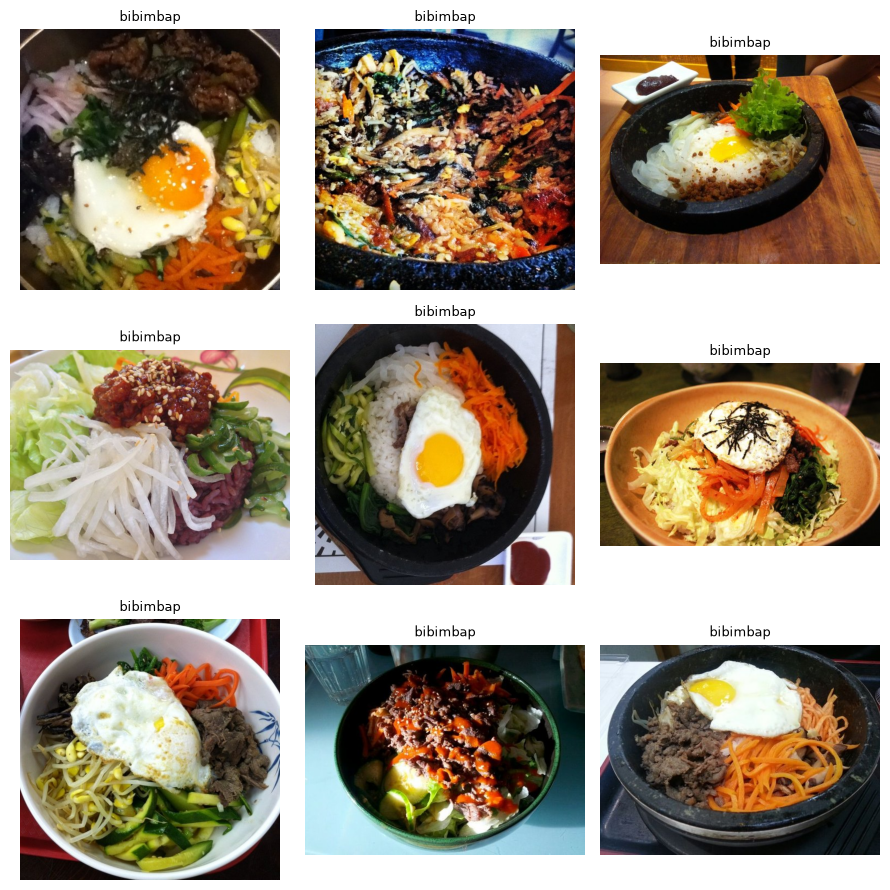

In [28]:
# Visualizing a sample of minimum perceived brightness food images
numeric_label                   = LABELS_IDX_LOOKUP[LABELS_IDX_LOOKUP['Label Name'] == min_label]['Label Index'].iloc[0]
min_perceived_brightness_images = [i for i in food_all if i['label'] == numeric_label]

n, cols, seed = 9, 3, 42
idxs = random.Random(seed).sample(range(len(min_perceived_brightness_images)), n)
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = min_perceived_brightness_images[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]], fontsize=9)
plt.tight_layout(); plt.show()

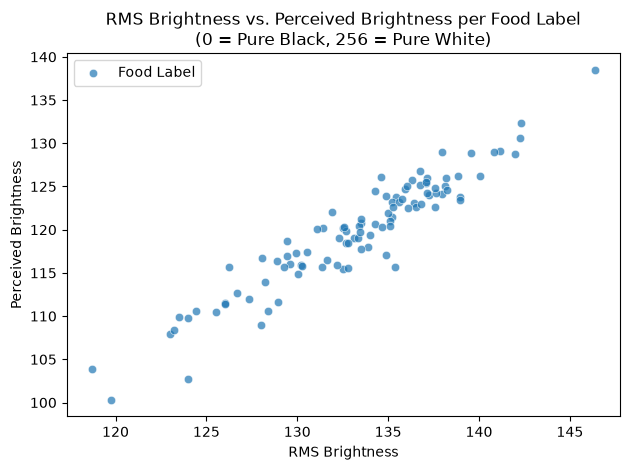

In [29]:
sns.scatterplot(
    x=food_label_brightness['RMS Brightness'],
    y=food_label_brightness['Perceived Brightness'],
    alpha=0.7
)
plt.title('RMS Brightness vs. Perceived Brightness per Food Label\n(0 = Pure Black, 256 = Pure White)')
plt.legend(['Food Label'])
plt.tight_layout()
plt.show()

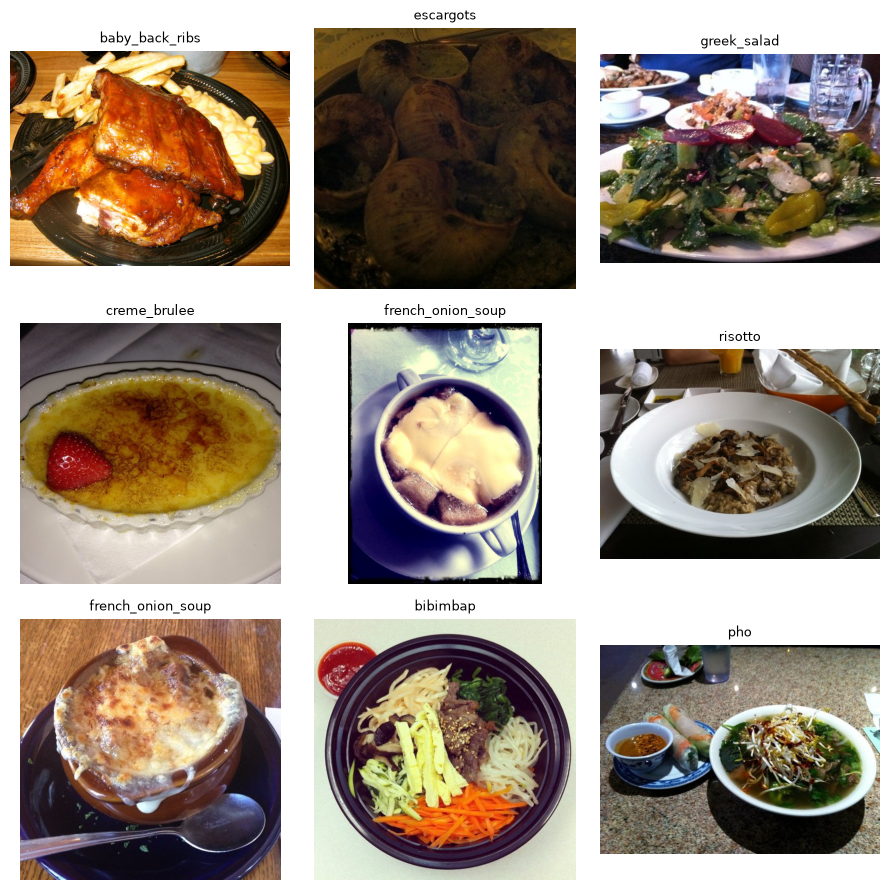

In [30]:
# View a new random sample of images
n, cols, seed = 9, 3, 476
idxs = random.Random(seed).sample(range(len(food_all)), n)
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = food_all[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]], fontsize=9)
plt.tight_layout(); plt.show()

Checking for dark, light, odd_aspect_ratio, low_information, exact_duplicates, near_duplicates, blurry, grayscale, odd_size images ...


Computing scores:   0%|          | 0/101000 [00:00<?, ?it/s]

Computing hashes:   0%|          | 0/101000 [00:00<?, ?it/s]

Issue checks completed. 452 issues found in the dataset. To see a detailed report of issues found, use imagelab.report().
Issues found in images in order of severity in the dataset

|    | issue_type       |   num_images |
|---:|:-----------------|-------------:|
|  0 | blurry           |          137 |
|  1 | exact_duplicates |          118 |
|  2 | dark             |           98 |
|  3 | near_duplicates  |           92 |
|  4 | odd_aspect_ratio |            3 |
|  5 | grayscale        |            3 |
|  6 | low_information  |            1 |
|  7 | light            |            0 |
|  8 | odd_size         |            0 | 

---------------------- blurry images -----------------------

Number of examples with this issue: 137
Examples representing most severe instances of this issue:



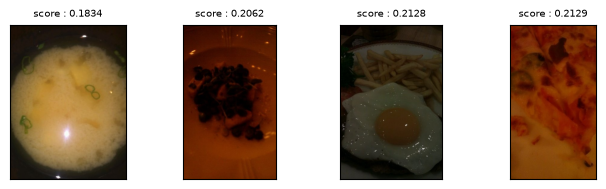

----------------- exact_duplicates images ------------------

Number of examples with this issue: 118
Examples representing most severe instances of this issue:

Set: 0


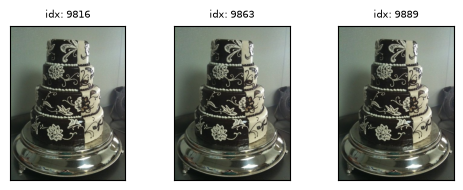

Set: 1


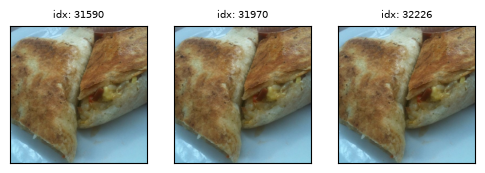

Set: 2


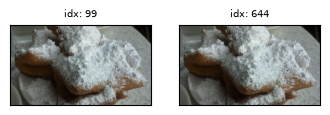

Set: 3


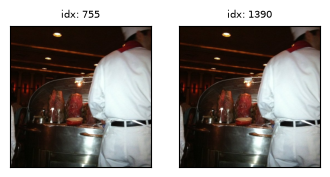

----------------------- dark images ------------------------

Number of examples with this issue: 98
Examples representing most severe instances of this issue:



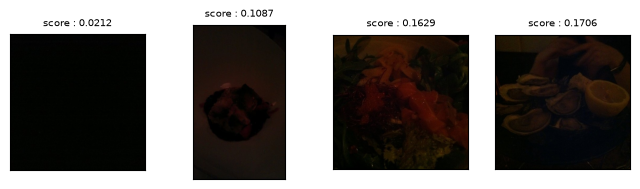

------------------ near_duplicates images ------------------

Number of examples with this issue: 92
Examples representing most severe instances of this issue:

Set: 0


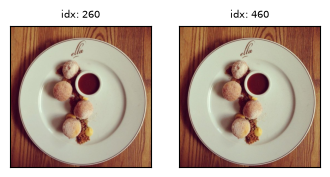

Set: 1


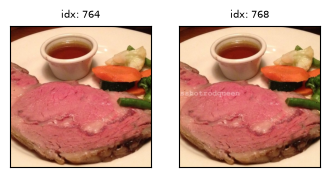

Set: 2


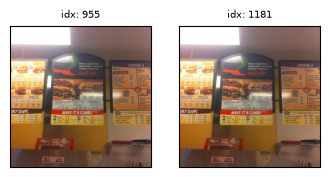

Set: 3


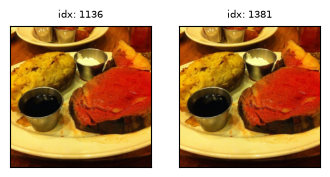

----------------- odd_aspect_ratio images ------------------

Number of examples with this issue: 3
Examples representing most severe instances of this issue:



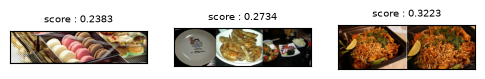

--------------------- grayscale images ---------------------

Number of examples with this issue: 3
Examples representing most severe instances of this issue:



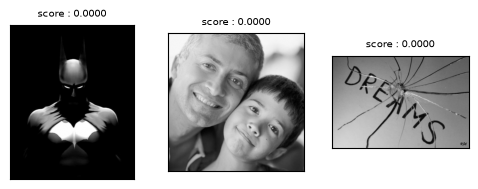

------------------ low_information images ------------------

Number of examples with this issue: 1
Examples representing most severe instances of this issue:



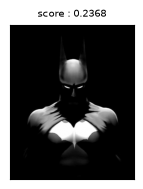

In [ ]:
# Using cleanvision to inspect dataset quality (checks duplicates, darkness, lightness, etc.)
from cleanvision import Imagelab

# ignore warnings for better notebook readability
#       Used Gemini: https://share.gemini.google/C0l61UHKiN7o
os.environ["PYTHONWARNINGS"] = "ignore"

imagelab = Imagelab(hf_dataset=food_all, image_key='image')
imagelab.find_issues()
imagelab.report()

# Source for checking data quality: https://cleanvision.readthedocs.io/en/latest/tutorials/huggingface_dataset.html

In [32]:
imagelab.issues.head()

,odd_size_score,is_odd_size_issue,odd_aspect_ratio_score,is_odd_aspect_ratio_issue,low_information_score,is_low_information_issue,light_score,is_light_issue,grayscale_score,is_grayscale_issue,dark_score,is_dark_issue,blurry_score,is_blurry_issue,exact_duplicates_score,is_exact_duplicates_issue,near_duplicates_score,is_near_duplicates_issue
0,0.928571,False,0.750000,False,0.889266,False,0.947072,False,1,False,0.751984,False,0.429014,False,1.0,False,1.0,False
1,0.928571,False,1.000000,False,0.937820,False,0.874974,False,1,False,0.971737,False,0.474234,False,1.0,False,1.0,False
2,0.927368,False,0.748047,False,0.939400,False,0.936729,False,1,False,0.991625,False,0.480232,False,1.0,False,1.0,False
3,0.884220,False,0.679688,False,0.903561,False,0.830981,False,1,False,0.892534,False,0.471804,False,1.0,False,1.0,False
4,0.928571,False,1.000000,False,0.917898,False,0.691988,False,1,False,0.991697,False,0.459467,False,1.0,False,1.0,False


In [41]:
# Check for exact and near duplicate sets
exact_duplicates_idx = imagelab.issues[imagelab.issues['is_exact_duplicates_issue'] == True]
total_exact_duplicates = len(exact_duplicates_idx)
exact_duplicate_sets_idx = imagelab.info['exact_duplicates']['sets']
print(f'There are {len(exact_duplicate_sets_idx)} duplicate image sets in the food101 dataset')

near_duplicates_idx = (
    imagelab.issues.query('is_near_duplicates_issue')
    .sort_values(by='near_duplicates_score', ascending=False)
    .index.tolist()
)
total_near_duplicates = len(near_duplicates_idx)
near_duplicate_sets_idx = imagelab.info['near_duplicates']['sets']
print(f'There are {len(near_duplicate_sets_idx)} near duplicate image sets in the food101 dataset')

There are 58 duplicate image sets in the food101 dataset
There are 46 near duplicate image sets in the food101 dataset


### Non-food images that are also mislabeled

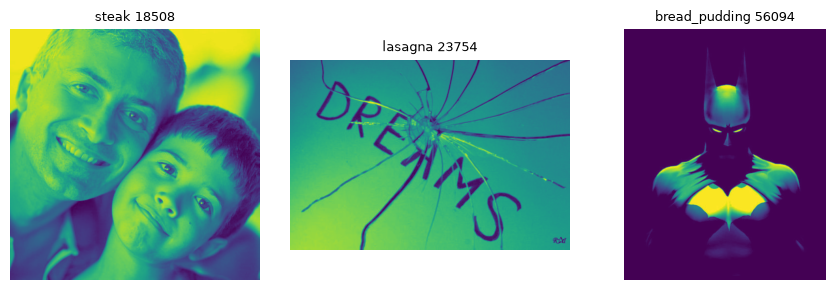

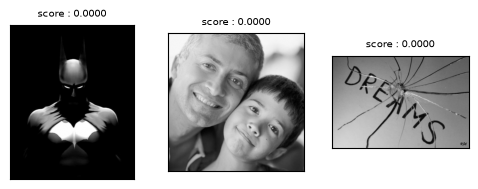

In [60]:
# Check grayscale images since some art not food
grayscale_imgs = imagelab.issues[imagelab.issues['is_grayscale_issue'] == True].index

# Visualize all 3 grayscale images and its labels
n, cols, seed = 3, 3, 476
idxs = grayscale_imgs
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = food_all[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

imagelab.visualize(issue_types=["grayscale"])

Notes:

- Non-food items have incorrect food labels. Unsure why these items were flagged for grayscale issues when the raw images are colored but clearvision detected them as grayscale.

These should likely be dropped, unless there are significant more non-food images to justify adding a singular non-food label.

In [65]:
# Keep track of mislabeled images for potential removal/label changes
MISLABELED = [
    {
        'Index'                 : 18508,
        'Raw Label'             : 'steak',
        'Actual Description'    : 'people'
    },
    {
        'Index'                 : 23754,
        'Raw Label'             : 'lasagna',
        'Actual Description'    : 'broken glass and text'
    },
    {
        'Index'                 : 56094,
        'Raw Label'             : 'bread_pudding',
        'Actual Description'    : 'batman'
    }
]

MISLABELED_IMAGES_DF = pd.DataFrame(MISLABELED)
MISLABELED_IMAGES_DF

,Index,Raw Label,Actual Description
0,18508,steak,people
1,23754,lasagna,broken glass and text
2,56094,bread_pudding,batman


### Dark Images

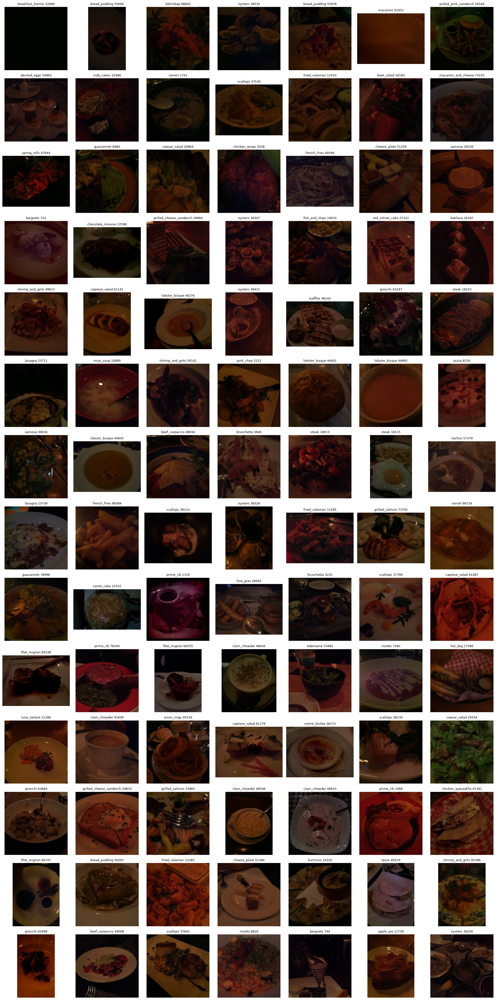

In [ ]:
# Check dark images (sorted darkest to lightest)
dark_imgs = imagelab.issues[imagelab.issues['is_dark_issue'] == True].sort_values(by='dark_score').index
# len(dark_imgs) / 14

# Visualize all 98 dark images and its labels
n, cols, seed = 98, 7, 476
idxs = dark_imgs
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = food_all[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

Notes:

- ``breakfast_burrito (index: 32090)`` does not seem usable since it is almost completely black.
- ``macarons 61951`` does not seem usable since it is blurry and doesn't look like macarons.

Overall, lighting could potentially be adjusted/normalized when possible or drop specific samples and account for stratified split to avoid bias.

In [68]:
breakfast_burrito = pd.DataFrame(
    [{
        'Index'                 : 32090,
        'Raw Label'             : 'breakfast_burrito',
        'Actual Description'    : 'completely black, potential qualified for removal'
    }]
)

macarons = pd.DataFrame(
    [{
        'Index'                 : 61951,
        'Raw Label'             : 'macarons',
        'Actual Description'    : 'too blurry, unlike macarons'
    }]
)

MISLABELED_IMAGES_DF = pd.concat([MISLABELED_IMAGES_DF, breakfast_burrito, macarons])
MISLABELED_IMAGES_DF


,Index,Raw Label,Actual Description
0,18508,steak,people
1,23754,lasagna,broken glass and text
2,56094,bread_pudding,batman
0,32090,breakfast_burrito,"completely black, potential qualified for removal"
0,61951,macarons,"too blurry, unlike macarons"


### Odd aspect ratios

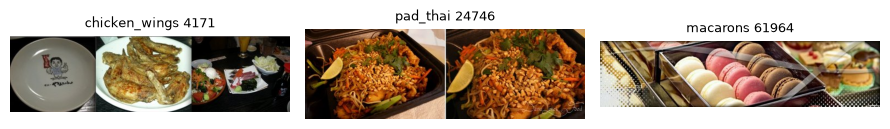

In [ ]:
# Check odd aspect ratio images
odd_aspect_ratio_imgs = imagelab.issues[imagelab.issues['is_odd_aspect_ratio_issue'] == True].index

# Visualize all 3 odd aspect ratio images and its labels
n, cols, seed = 3, 3, 476
idxs = odd_aspect_ratio_imgs
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = food_all[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

Notes:

- interesting cases with these images because the first 2 images are multi-image compositions which could result in some issues potentially

Potential options could be to crop the images for the first 2 images so that it only includes one example of it: 
  - 1st should include the middle image within itself since thats where the chicken wings seem to be
  - 2nd should include either the first or second image within itself since they are just different angles

### Check issues report per class label

In [ ]:
# update copy of results with class label index and name
issues_df               = imagelab.issues.copy()
issues_df['label_idx']  = [food_all[i]['label'] for i in range(len(issues_df))]
issues_df['label_name'] = issues_df['label_idx'].map(lambda i: food_label_names[i])
issues_df.head()

,odd_size_score,is_odd_size_issue,odd_aspect_ratio_score,is_odd_aspect_ratio_issue,low_information_score,is_low_information_issue,light_score,is_light_issue,grayscale_score,is_grayscale_issue,dark_score,is_dark_issue,blurry_score,is_blurry_issue,exact_duplicates_score,is_exact_duplicates_issue,near_duplicates_score,is_near_duplicates_issue,label_idx,label_name
0,0.928571,False,0.750000,False,0.889266,False,0.947072,False,1,False,0.751984,False,0.429014,False,1.0,False,1.0,False,6,beignets
1,0.928571,False,1.000000,False,0.937820,False,0.874974,False,1,False,0.971737,False,0.474234,False,1.0,False,1.0,False,6,beignets
2,0.927368,False,0.748047,False,0.939400,False,0.936729,False,1,False,0.991625,False,0.480232,False,1.0,False,1.0,False,6,beignets
3,0.884220,False,0.679688,False,0.903561,False,0.830981,False,1,False,0.892534,False,0.471804,False,1.0,False,1.0,False,6,beignets
4,0.928571,False,1.000000,False,0.917898,False,0.691988,False,1,False,0.991697,False,0.459467,False,1.0,False,1.0,False,6,beignets


In [95]:
# Isolate issue flags
issue_cols = [i for i in issues_df.columns.tolist() if not i.startswith('label') and i.endswith('_issue')]

# Get total images per issue by food label class
issues_by_class = issues_df.groupby('label_name')[issue_cols].agg('sum')

# Get total issues per food label class
issues_by_class['total_issues'] = issues_by_class[issue_cols].sum(axis=1)

# Sort by most issues descending order
issues_by_class = issues_by_class.sort_values(by='total_issues', ascending=False)

# Only show food class labels that have at least 1 issue
imgs_with_issues = issues_by_class[issues_by_class['total_issues'] > 0]

print(f'Out of {len(food_label_names)} food label classes, there are {len(imgs_with_issues)} food label classes with at least 1 image quality issue.')
imgs_with_issues

Out of 101 food label classes, there are 92 food label classes with at least 1 image quality issue.


,is_odd_size_issue,is_odd_aspect_ratio_issue,is_low_information_issue,is_light_issue,is_grayscale_issue,is_dark_issue,is_blurry_issue,is_exact_duplicates_issue,is_near_duplicates_issue,total_issues
label_name,,,,,,,,,,
prime_rib,0,0,0,0,0,3,0,5,10,18
miso_soup,0,0,0,0,0,1,16,0,0,17
clam_chowder,0,0,0,0,0,4,9,2,0,15
gnocchi,0,0,0,0,0,3,6,2,2,13
fried_calamari,0,0,0,0,0,3,1,2,4,10
...,...,...,...,...,...,...,...,...,...,...
gyoza,0,0,0,0,0,0,1,0,0,1
donuts,0,0,0,0,0,0,1,0,0,1
frozen_yogurt,0,0,0,0,0,0,1,0,0,1


In [96]:
# function for inspecting specific food label images by its issue type
def inspect_img_issues(class_name, issue_type):
    # Filter issues_df rows by class and issue type
    mask   = ((issues_df['label_name'] == class_name) & (issues_df[issue_type] == True))
    subset = issues_df[mask]

    # get image indices
    indices = subset.index.tolist()
    print(f"Found {len(indices)} images for class '{class_name}' with issue '{issue_type}'.")

    if len(indices) == 0:
        print(f"No images found for '{class_name}' with issue '{issue_type}'.")
        return

    # Display images with maximum 6 images per row
    num_images = len(indices)
    n, cols = num_images, 6
    idxs = indices
    rows = math.ceil(n/cols)

    plt.figure(figsize=(3*cols, 3*rows))
    for i, idx in enumerate(idxs, 1):
        ex = food_all[idx]
        plt.subplot(rows, cols, i)
        plt.imshow(ex["image"]); plt.axis("off")
        plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
    plt.suptitle(f'Class: {class_name} | Issue: {issue_type}', fontweight='bold')
    plt.tight_layout(); plt.show()

In [98]:
issue_cols

['is_odd_size_issue',
 'is_odd_aspect_ratio_issue',
 'is_low_information_issue',
 'is_light_issue',
 'is_grayscale_issue',
 'is_dark_issue',
 'is_blurry_issue',
 'is_exact_duplicates_issue',
 'is_near_duplicates_issue']

In [99]:
odd_size            = issues_df[issues_df['is_odd_size_issue'] > 0]
odd_aspect_ratio    = issues_df[issues_df['is_odd_aspect_ratio_issue'] > 0]
low_info            = issues_df[issues_df['is_low_information_issue'] > 0]
light               = issues_df[issues_df['is_light_issue'] > 0]
grayscale           = issues_df[issues_df['is_grayscale_issue'] > 0]
dark                = issues_df[issues_df['is_dark_issue'] > 0]
blurry              = issues_df[issues_df['is_blurry_issue'] > 0]
exact_dup           = issues_df[issues_df['is_exact_duplicates_issue'] > 0]
near_dup            = issues_df[issues_df['is_near_duplicates_issue'] > 0]

In [118]:
# Display total image count per class for each issue type
issues = {
    'Odd Size'              : odd_size,
    'Odd Aspect Ratio'      : odd_aspect_ratio,
    'Low Information'       : low_info,
    'Light'                 : light,
    'Grayscale'             : grayscale,
    'Dark'                  : dark,
    'Blurry'                : blurry,
    'Exact Duplicate'       : exact_dup,
    'Near Duplicate'        : near_dup
}

print('----     NUMBER OF IMAGES PER CLASS BY ISSUE TYPE    ----\n')

for title, type in issues.items():
    print(f'                    --- {title} ---')
    counts = type['label_name'].value_counts()

    # only display counts that are at least 1
    if len(counts) > 0:
        print(counts.to_string())
    else:
        print('None found.')
    print("\n" + "="*60 + "\n")

----     NUMBER OF IMAGES PER CLASS BY ISSUE TYPE    ----

                    --- Odd Size ---
None found.


                    --- Odd Aspect Ratio ---
label_name
chicken_wings    1
pad_thai         1
macarons         1


                    --- Low Information ---
label_name
bread_pudding    1


                    --- Light ---
None found.


                    --- Grayscale ---
label_name
steak            1
lasagna          1
bread_pudding    1


                    --- Dark ---
label_name
oysters                    5
scallops                   5
lobster_bisque             4
clam_chowder               4
fried_calamari             3
steak                      3
bread_pudding              3
shrimp_and_grits           3
filet_mignon               3
caprese_salad              3
gnocchi                    3
prime_rib                  3
beef_carpaccio             2
lasagna                    2
grilled_cheese_sandwich    2
samosa                     2
french_fries               2
cheese

Found 10 images for class 'prime_rib' with issue 'is_near_duplicates_issue'.


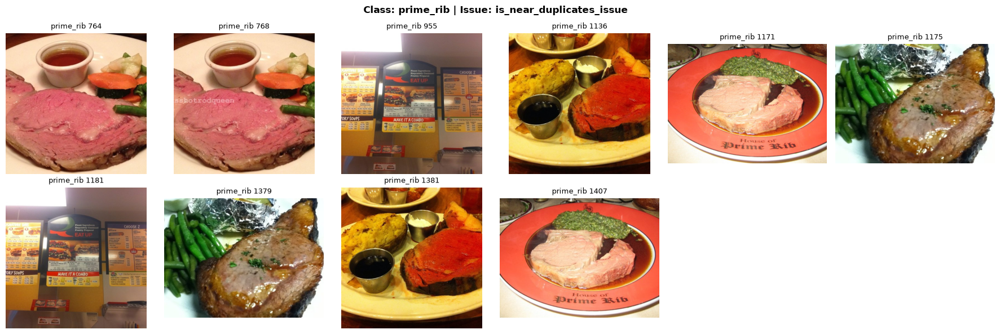

In [97]:
inspect_img_issues('prime_rib', 'is_near_duplicates_issue')

### Graded Questions (2 pts each)

Write **a coherent response of approximately 100–150 words per question** in its designated Python answer variable. Be specific to your dataset and refer to relevant code, tables, plots, and numerical results where appropriate. Put supporting code in the programming cells rather than in your written answers. These word counts indicate the expected depth of explanation, not rigid limits.

A. **Dataset Summary:**  
   Describe your chosen dataset  (as if explaining to your *clueless boss* what you are working on).
   - State which dataset you are going to use.   
   - What kind of data does it contain (images or text)?  
   - How many samples and classes are there?  
   - What is the task you’ll perform (classification into what categories)?
   - What is the potential business use for this dataset?

In [ ]:
# Your answer here, NOT in the next cell

a1a = """
Write your answer here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1a = {a1a}")

B. **Initial Observations:**  
   What stood out to you from your EDA?  
   - Did you notice any imbalanced or ambiguous classes?  
   - Any patterns, anomalies, or potential sources of bias?  
   - For images: note any variation in lighting, composition, or color.  
   - For text: mention redundancy, topic overlap, or very short examples.

In [ ]:
# Your answer here, NOT in the next cell

a1b = """
Write your answer here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1b = {a1b}")

C. **Challenges & Implications:**  
   Based on your inspection, what challenges might affect model performance or training (e.g., imbalance, ambiguous labels, variable quality)?  

In [ ]:
# Your answer here, NOT in the next cell

a1c = """
Write your answer here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1c = {a1c}")

D. **Preparation Ideas:**  
   What data-cleaning or preprocessing steps might help address these issues?  
   (You will not implement these yet—just describe what you might do later.)

In [ ]:
# Your answer here, NOT in the next cell

a1d = """
Write your answer here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1d = {a1d}")

E. **Reflection:**  
   Why did you choose this dataset over the other one?  
   - What makes it more interesting, realistic, or relevant for you?  
   - What do you expect to learn from working with it?

In [ ]:
# Your answer here, NOT in the next cell

a1e = """
Write your answer here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1e = {a1e}")

## Problem 2 — Frame the Problem (15 pts)

#### Objective

Identify the **key challenges** in your chosen dataset and outline **practical solutions** you would try, plus how you’ll **evaluate** them later.

#### Steps to follow

1. **Diagnose likely challenges (from your EDA):**

   Examples:
   * **Class imbalance:**
     Report label counts and an imbalance ratio (max / median). List any minority classes.
   * **Length/size variance:**
     For text, show length percentiles (50/75/90/95) and estimate truncation rate at candidate `max_text_length`s (e.g., 256/300/512). For images, summarize native resolutions.
   * **Noise/duplicates/leakage:**
     Note empty or malformed items, near-duplicates, and how you would prevent cross-split leakage.
   * **Ambiguous/overlapping labels:**
     Give 2–3 example pairs you expect to be confusable and why.
   * **Compute constraints:**
     Briefly state limits (RAM/GPU/CPU) that might affect batch size, sequence length, or image size.

2. **Map each challenge to a concrete solution plan:**

   Examples:
   * **Imbalance →** `class_weight` or oversampling; report which one you’d try first and why.
   * **Length/size →** pick a target `max_text_length` (e.g., 95th percentile) with masking; for images, standardize resize/crop and basic augmentation.
   * **Noise/duplicates →** dedupe (hash/near-dup), drop empty/very short items, document any relabeling.
   * **Ambiguity →** consider merging labels (if justified), or add features (bigrams/char-ngrams; simple image augmentations).
   * **Overfitting risk →** early stopping on your primary metric, dropout/weight decay, freeze-then-finetune plan (for pretrained features).

3. **Explore appropriate evaluation metrics:**

   Examples:
   * **Primary metric:** pick one aligned to your data (e.g., **macro-F1** if imbalanced; accuracy if balanced).
   * **Secondary metric(s):** per-class precision/recall, confusion matrix.
   * **Protocol:** stratified Train/Val/Test (e.g., 70/15/15), fixed seed, leakage checks.

4. **Answer the graded questions below.**



In [ ]:
# Your code here, add as many cells as you like. Provide organization and structure by appropriate comments, labels, and variable names. Explain what
# you are doing in case you come back to this in a year. 



### Graded Questions (3 pts each)

Write **a coherent response of approximately 75–125 words per question** in its designated Python answer variable. Be specific to your dataset and refer to relevant code, tables, plots, and numerical results where appropriate. Put supporting code in the programming cells rather than in your written answers. These word counts indicate the expected depth of explanation, not rigid limits. Straightforward factual questions (such as identifying inputs and outputs) may be answered more briefly when fully addressed.

A. **State the prediction task**  
   - Describe what your model will predict (the *label*).  
   - *Examples:*  
     - “Given a photo of food, predict which of 101 categories it belongs to.”  
     - “Given a news headline + summary, predict its topical category.”  

In [ ]:
# Your answer here, NOT in the next cell

a2a = """
Write your answer here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2a = {a2a}")

B. **Define inputs and outputs**  
   - *Inputs:* what information the model receives (e.g., pixel data, tokenized text).  
   - *Outputs:* the categorical label the model will predict.  

In [ ]:
# Your answer here, NOT in the next cell

a2b = """
Write your answer here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2b = {a2b}")

C. **Identify possible challenges**  
   - Imbalanced classes, noisy data, ambiguous labels, overlapping features, or missing data  
   - *Images:* variation in lighting, color, composition, or size.  
   - *Text:* class imbalance, duplicate stories, short or ambiguous headlines.  

In [ ]:
# Your answer here, NOT in the next cell

a2c = """
Write your answer here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2c = {a2c}")

D. **Propose how you will prepare or improve the data to address the challenges**  
   - *Images:* resizing, normalization, data augmentation (flips, rotations, brightness, color jitter).  
   - *Text:* tokenization, stop-word removal, TF-IDF, class balancing, embeddings (choose an embedding approach and specify its vector size). 

In [ ]:
# Your answer here, NOT in the next cell

a2d = """
Write your answer here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2d = {a2d}")

E. **Specify success metrics**  
   - Identify the metrics you plan to use to evaluate model performance—typically **accuracy** and/or **F1-score**, which are standard for classification tasks.  
   - Briefly explain **why** these metrics are appropriate for your dataset and goal. For instance, accuracy may suffice for well-balanced datasets, while F1-score better reflects performance when some classes are under-represented.
   - If your dataset is **imbalanced**, consider computing **per-class metrics** (e.g., precision, recall, or F1 for each label) or **macro-averaged** scores, which give equal weight to each class regardless of its size—ensuring that minority classes are evaluated fairly.
In some cases, weighted averages (which weight classes by their frequency) or **confusion matrices** can also provide useful insight.
> You haven't run any models yet, and we haven’t studied every possible metric, but you’re encouraged to ask your favorite generative AI tool which evaluation metrics might best fit your dataset!
   - Clearly state how you will interpret success—for example, “Our goal is to achieve at least 80% overall accuracy without large per-class disparities.”

In [ ]:
# Your answer here, NOT in the next cell

a2e = """
Write your answer here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2e = {a2e}")

## Problem 3 — Data Preparation and Splits (30 pts)

### Goals

Implement the **data preparation and preprocessing steps** that you proposed in **Problems 1–2**. You’ll clean, normalize, and split your data so that it’s ready for modeling and reproducible modeling.

### Steps to Follow

1. **Load your chosen dataset**

   * Use `datasets.load_dataset()` from **Hugging Face** to load **Food-101** or **HuffPost**.
   * Display basic information (e.g., number of samples, feature names, example entries).

2. **Apply cleaning and normalization**

   * **Images:**

     * Ensure all images are in RGB format.
     * Resize or crop to a consistent shape (e.g., `224 × 224`).
     * Drop or fix any corrupted files.
   * **Text:**

     * Concatenate headline + summary (for HuffPost).
     * Strip whitespace, convert to lowercase if appropriate, and remove empty samples.
     * Optionally remove duplicates or extremely short entries.

3. **Standardize or tokenize the inputs**

   * **Images:**

     * Normalize pixel values (e.g., divide by 255.0).
     * Define a minimal augmentation pipeline (e.g., random flip, crop, or rotation).
   * **Text:**

     * Create a tokenizer or `TextVectorization` layer.
     * Set a target `max_length` based on your analysis from your earlier exploration in this notebook (e.g., 95th percentile).
     * Apply padding/truncation and build tensors for input + labels.

4. **Handle dataset-specific challenges**

   * If you identified **class imbalance**, compute label counts and, if needed, create a dictionary of `class_weights`.
   * If you noted **length or size variance**, verify that your truncation or resizing works as intended.
   * If you planned **noise filtering**, include the cleaning step and briefly explain your criteria (e.g., remove items with missing text or unreadable images).

5. **Create reproducible splits**

   * Split your cleaned dataset into **train**, **validation**, and **test** subsets (e.g., 80 / 10 / 10).
   * Use a fixed random seed for reproducibility (`random_seed = 42`).
   * Use **stratified splits**  (e.g., with `train_test_split` and `stratify = labels`).
   * Display the size of each subset.

6. **Document your pipeline**

   * Summarize your preprocessing steps clearly in Markdown or code comments.
   * Save or display a few representative examples after preprocessing to confirm the transformations are correct.




**Test-set policy:** Create and verify the test split, but **do not train on or evaluate models against it** in this milestone. Fit preprocessing parameters (e.g. vocabulary, scaling) on training data only; apply the fitted transformations to validation and test examples. Apply random augmentation to training data only.


In [ ]:
# Your code here; add as many cells as you need but make it clear what the structure is. 


### Grading for Problem 3 (30 pts)

- **Implementation (18 pts):** correct data loading and cleaning; appropriate preprocessing; reproducible, separate train/validation/test splits with leakage prevention; and checks/outputs demonstrating that the prepared data are suitable for modeling.
- **Written answers (12 pts):** Questions A–D, **3 pts each**. Explain the actual implementation and cite your notebook results.

### Graded Questions (3 pts each)

Write **a coherent response of approximately 100–150 words per question** in its designated Python answer variable. Be specific to your dataset and refer to relevant code, tables, plots, and numerical results where appropriate. Put supporting code in the programming cells rather than in your written answers. These word counts indicate the expected depth of explanation, not rigid limits.

A. **Data Loading and Cleaning:**
   Describe how you loaded your dataset and the key cleaning steps you implemented (e.g., handling missing data, normalizing formats, or removing duplicates).



In [ ]:
# Your answer here, NOT in the next cell

a3a = """
Write your answer here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3a = {a3a}")

B. **Preprocessing and Standardization:**
   Summarize your preprocessing pipeline. Include any normalization, tokenization, resizing, or augmentation steps, and explain why each was necessary for your dataset.
  

In [ ]:
# Your answer here, NOT in the next cell

a3b = """
Write your answer here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3b = {a3b}")

C. **Train/Validation/Test Splits:**
   Explain how you divided your data into subsets, including the split ratios, random seed, and any stratification or leakage checks you used to verify correctness.


In [5]:
# Your answer here, NOT in the next cell

a3c = """
Write your answer here.
"""

In [6]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3c = {a3c}")

a3c = 
Write your answer here.



D. **Class Distribution and Balance:**
   Report your label counts and describe any class imbalances you observed. If applicable, explain how you addressed them (e.g., weighting, oversampling, or data augmentation).


In [7]:
# Your answer here, NOT in the next cell

a3d = """
Write your answer here.
"""

In [8]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3d = {a3d}")

a3d = 
Write your answer here.



## Problem 4 — Baseline Model (30 pts)

### Goal

Build and train a **simple, fully functional baseline model** to establish a reference level of performance for your dataset.
This baseline will help you evaluate whether later architectures and fine-tuning steps actually improve results.


### Steps to Follow

1. **Construct a baseline model**

   * **Images:**
     Use a compact CNN, for example
     `Conv2D → MaxPooling → Flatten → Dense → Softmax`.
   * **Text:**
     Use a small embedding-based classifier such as
     `Embedding → GlobalAveragePooling → Dense → Softmax`.
   * Keep the model small enough to train in minutes on Colab.

2. **Compile the model**

   * Optimizer: `Adam` or `AdamW`.
   * Loss: Use `categorical_crossentropy` for one-hot-encoded labels or `sparse_categorical_crossentropy` for integer class labels.
   * Metrics: at least `accuracy`; add `F1` if appropriate.

3. **Train and validate**

   * Use **early stopping** on validation loss with a patience of approximately 5 epochs.
   * Record number of epochs trained and total runtime.

4. **Visualize results**

   * Plot **training vs. validation accuracy and loss**.
   * Carefully observe: does the model underfit, overfit, or generalize reasonably?

5. **Report baseline performance**

   * The most important metric is the **validation accuracy at the epoch of minimum validation loss**; this serves as your **benchmark** for all later experiments in the final project.
   * **Do not evaluate on the test set yet.** Report validation performance only. Preserve the test split for final evaluation.

In [9]:
# Your code here; add as many cells as you need but make it clear what the structure is. 


### Grading for Problem 4 (30 pts)

- **Implementation (18 pts):** a functional, appropriate baseline model; correct compilation and training; appropriate use of training and validation sets (no test evaluation); learning curves; and reproducible, clearly reported validation results.
- **Written answers (12 pts):** Questions A–D, **3 pts each**. Explain the actual model, training behavior, and results.

### Graded Questions (3 pts each)

Write **a coherent response of approximately 100–150 words per question** in its designated Python answer variable. Be specific to your dataset and refer to relevant code, tables, plots, and numerical results where appropriate. Put supporting code in the programming cells rather than in your written answers. These word counts indicate the expected depth of explanation, not rigid limits.

A. **Model Architecture:**
   Describe your baseline model and justify why this structure suits your dataset.

In [10]:
# Your answer here, NOT in the next cell

a4a = """
Write your answer here.
"""

In [11]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4a = {a4a}")

a4a = 
Write your answer here.



B. **Training Behavior:**
   Summarize the model’s training and validation curves. What trends did you observe?

In [12]:
# Your answer here, NOT in the next cell

a4b = """
Write your answer here.
"""

In [13]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4b = {a4b}")

a4a = 
Write your answer here.



 C. **Baseline Metrics:**
   Report validation metrics only. What does this performance tell you about dataset difficulty?

In [14]:
# Your answer here, NOT in the next cell

a4c = """
Write your answer here.
"""

In [15]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4c = {a4c}")

a4a = 
Write your answer here.



  D. **Reflection:**
   What are the main limitations of your baseline? Which specific improvements (depth, regularization, pretraining) would you try next?
  

In [16]:
# Your answer here, NOT in the next cell

a4d = """
Write your answer here.
"""

In [17]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4d = {a4d}")

a4a = 
Write your answer here.



## Final checks and AI-use disclosure (read but not graded)

**AI question:** Describe what use you made of generative AI tools in preparing this milestone, consistent with CDS policy. Include what you used the tools for and how you verified the results.

**Your answer here:**

### Submission checklist

- [ ] I explored both datasets, chose one, and removed the unused dataset’s starter section.
- [ ] The submitted notebook has my name and answers to Problems 1–4.
- [ ] The notebook contains the code, relevant outputs, plots, and training/validation metrics for the baseline.
- [ ] The test set was created but **not used to make modeling decisions or report baseline test performance**.
- [ ] I restarted the kernel and ran the notebook from top to bottom, without errors.
- [ ] I documented random seeds, dataset sampling, dependencies, and AI-tool use.


## Appendix: A quick guide to Hugging Face Datasets

#### 1) What are they?

* A **table-like** dataset: rows = examples, columns = named fields (e.g., `"image"`, `"label"`, `"headline"`).
* Backed by **Apache Arrow** → fast, memory-efficient, lazy transforms.
* Two core objects:

  * `Dataset` — one table of rows/columns.
  * `DatasetDict` — a dict of splits, e.g. `{"train": Dataset, "val": Dataset, "test": Dataset}`.


#### 2) Load and inspect

```python
from datasets import load_dataset

# Food-101 (images)
food = load_dataset("food101", split="train+validation")  # both splits at once
len(food), food.column_names, food.features
# -> (≈101000, ['image','label'], {'label': ClassLabel(num_classes=101, names=[...])})

# Access by name (not by numeric column index!)
row0 = food[0]
img0, y0 = row0["image"], row0["label"]     # PIL image, int id
label_names = food.features["label"].names
label_names[y0]
```

For text (HuffPost JSON mirror):

```python
url = "https://huggingface.co/datasets/khalidalt/HuffPost/resolve/main/News_Category_Dataset_v2.json"
huff = load_dataset("json", data_files=url, split="train")
huff.column_names  # e.g. ['headline','short_description','category','authors','link','date']
```


#### 3) Common transforms

`Dataset`s are **immutable**: ops return a new dataset.

* **Map** (add/modify columns):

```python
def mk_text(ex):
    h = (ex.get("headline") or "").strip()
    s = (ex.get("short_description") or "").strip()
    return {"text": (h + " [SEP] " + s).strip()}

huff = huff.map(mk_text)  # adds 'text' column
```

* **Class-encode** labels (strings → integers with a vocabulary):

```python
from datasets.features import ClassLabel
if not isinstance(huff.features["category"], ClassLabel):
    huff = huff.class_encode_column("category")  # now ints with .names
```

* **Filter / select / rename / drop**:

```python
small = huff.select(range(5000))  # first 5k rows
huff = huff.remove_columns(["authors","link","date"])
huff = huff.rename_column("category", "label")
```


#### 4) Splitting & shuffling

```python
# Stratified 80/10/10 on Food-101 by 'label'
from datasets import DatasetDict
label_col = "label"

tmp = food.train_test_split(test_size=0.10, seed=42, stratify_by_column=label_col)
train_val = tmp["train"].train_test_split(test_size=1/9, seed=42, stratify_by_column=label_col)
ds = DatasetDict(train=train_val["train"], val=train_val["test"], test=tmp["test"])

len(ds["train"]), len(ds["val"]), len(ds["test"])
```

* `train_test_split` is **random by default** (reproducible with `seed=`).
* You typically **don’t need to pre-shuffle** datasets if your training dataloader already shuffles each epoch.


#### 5) Working with images

Use `with_transform` to apply on-the-fly resizing/augmentation and return tensors:

```python
import torchvision.transforms as T
from torch.utils.data import DataLoader
import torch, math, random

IM_SIZE = 224
train_tfms = T.Compose([T.RandomResizedCrop(IM_SIZE), T.RandomHorizontalFlip(), T.ToTensor()])
eval_tfms  = T.Compose([T.Resize(256), T.CenterCrop(IM_SIZE), T.ToTensor()])

def add_pixel_values(ex, tfms):  # ex['image'] -> ex['pixel_values']
    ex = dict(ex); ex["pixel_values"] = tfms(ex["image"]); return ex

train_t = ds["train"].with_transform(lambda ex: add_pixel_values(ex, train_tfms))
val_t   = ds["val"].with_transform(lambda ex: add_pixel_values(ex, eval_tfms))

def collate(batch):
    return {"pixel_values": torch.stack([b["pixel_values"] for b in batch]),
            "labels": torch.tensor([b["label"] for b in batch])}

train_loader = DataLoader(train_t, batch_size=64, shuffle=True,  collate_fn=collate)
val_loader   = DataLoader(val_t,   batch_size=64, shuffle=False, collate_fn=collate)
```

### 6) Working with Text

You can preprocess and tokenize text datasets using either a **transformer tokenizer** or a **linguistic pipeline like spaCy**, depending on your model type and goals.


#### Option A: Transformer Tokenizer (for fine-tuning models like BERT or DistilBERT)

Use a pretrained tokenizer with the Hugging Face `map` method to efficiently process your dataset in batches:

```python
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained("distilbert-base-uncased")

def tokenize(batch):
    return tok(batch["text"], truncation=True, padding="max_length", max_length=128)

tokenized = huff.map(
    tokenize,
    batched=True,
    remove_columns=[c for c in huff.column_names if c not in ("category", "label")]
)
```

This produces token IDs, attention masks, and other fields expected by transformer models.
Use this approach if your project involves fine-tuning pretrained language models.


#### Option B: spaCy Tokenization and Cleaning (for classical ML or custom preprocessing)

If you are **not using transformers**, or if you want to explore feature engineering (e.g., TF-IDF, word frequency, or embedding averages), you can preprocess text with **spaCy** instead.

```python
# !pip install spacy
# !python -m spacy download en_core_web_sm

import spacy
from datasets import load_dataset

nlp = spacy.load("en_core_web_sm", disable=["ner", "parser", "textcat"])
STOP = spacy.lang.en.stop_words.STOP_WORDS

def spacy_clean(batch):
    docs = list(nlp.pipe(batch["text"], batch_size=1000))
    cleaned = []
    for doc in docs:
        tokens = [t.lemma_.lower() for t in doc if t.is_alpha and not t.is_stop]
        cleaned.append(" ".join(tokens))
    return {"text_clean": cleaned, "len_tokens": [len(c.split()) for c in cleaned]}

huff = huff.map(
    spacy_clean,
    batched=True,
    batch_size=1000,
    remove_columns=[c for c in huff.column_names if c not in ("category", "label")]
)
```

The resulting column `text_clean` can be used with:

* `TfidfVectorizer` (Scikit-learn)
* `TextVectorization` (Keras)
* or any other custom embedding method.

> 💡 **Tip:** spaCy is ideal for lightweight NLP pipelines or for models that rely on explicit preprocessing (lemmatization, stopword removal). Transformer tokenizers, by contrast, expect *raw text* and handle subword tokenization internally.



#### 7) Slicing, concatenating, saving

```python
# Slicing
head_1000 = food.select(range(1000))
tail_10pct = food.select(range(int(0.9*len(food)), len(food)))

# Concatenate splits/datasets
from datasets import concatenate_datasets
all_train = concatenate_datasets([ds["train"], ds["val"]])

# Save / reload
ds.save_to_disk("food101_splits")
from datasets import load_from_disk
ds2 = load_from_disk("food101_splits")
```


#### 8) Quick “gotchas”

* **Columns by name** (strings), not numeric indices.
* Avoid converting huge columns to `list(...)` unless necessary; prefer vectorized ops with `map`, `filter`, `select`.
* `PYTHONHASHSEED` must be set **before** the Python process starts to matter; use explicit `seed=` arguments for reproducibility.
* Datasets print **previews** (e.g., `Column([6, 6, 6, ...])` is just the first few values).


#### 9) A minimal checklist to follow

1. `load_dataset(...)` → confirm `column_names`, `features`.
2. Build any needed columns (`"text"`), and **class-encode** labels if strings.
3. Make a **stratified 80/10/10** split (`train_test_split` ×2).
4. Do **EDA**: class counts, sample printouts or image grids.
5. For training:

   * **images** → `with_transform` + DataLoader
   * **text** → tokenizer via `.map(...)` + trainer/model pipeline
6. Save your `DatasetDict` with `save_to_disk(...)` (optional for text but handy, **don't** use it for big image datasets).

